# comparing_model6 — the stratum ladder: same ruler, shrinking stratum

`comparing_model4` §20 and `comparing_model5` §12 each report **one** number per arm: the AUROC
on a constructed contrast where the cross-cell-type average and the GM12878 truth disagree. That
number is the finding, but on its own it invites the obvious objection —

> *you changed the evaluation set until the models looked bad.*

This notebook answers that objection by **holding the metric completely fixed and varying only the
stratum**, in nested steps. Nothing here replaces §20 or §12; rung 3 below *is* §20/§12, and is
asserted against their published values as a gate.

## The ladder

Every rung uses the same class definition — "GM12878 CAGE above the noise floor" vs "below it" —
the same AUROC, the same region-level bootstrap, and the same arms. Each rung adds **exactly one**
restriction to the rung above it, so every rung is a strict subset of the one before:

| rung | positives | negatives | what it adds |
|---|---|---|---|
| **R0 · all bins** | any allowed bin, CAGE ≥ active | any allowed bin, CAGE < silent | — (the "is there a peak here" task) |
| **R1 · promoters** | R0 ∩ protein-coding TSS | R0 ∩ protein-coding TSS | element type matched on both sides |
| **R2 · + disagreement** | R1 ∩ cross-CT average **low** (< p50) | R1 ∩ cross-CT average **high** (≥ p90) | the generic expectation now points the *wrong* way |
| **R3 · + accessibility** | R2 ∩ open | R2 ∩ closed | an orthogonal assay confirms each call. **= §20 / §12** |

R2 is `comparing_model4` §20b / `comparing_model5` §12b's class definition; R3 is §20 / §12's.

## The two things that make this argument hard to dismiss

**1. The null is carried into every rung.** `[null] cross-CT average` — a predictor that outputs
nothing but the leave-GM12878-out mean over all other cell types — is scored on all four rungs
alongside the models. It should be *strong* on R0/R1 and land at *exactly 0.0* on R2/R3, because
R2 selects on it with a gap (negatives ≥ p90, positives < p50, so every negative outranks every
positive). That trajectory is the proof that the ruler did not change: a metric that had been
quietly redefined would not move the null in the direction the story predicts.

**2. No model output enters any class definition.** The strata are built from `TRUE`, `AVG_LOO` and
the accessibility assay only. This is selection on observables, not on the thing being scored.

## Reading the anchors — they are rung-dependent

On **R2/R3** the scale has three fixed anchors: **1.0** perfectly cell-type-specific, **0.5** no
cell-type information, **0.0** the output *is* the cross-cell-type average. On **R0/R1** those
anchors do **not** apply — the average is a *good* predictor there (it scores near the top), so
0.5 is ordinary chance and there is no "pure average" anchor at 0. Each panel is labelled
accordingly. Quoting the R2/R3 anchors under an R0/R1 number would be wrong.

## What is *not* claimed

R0 and R1 being near-ceiling is not a criticism of anyone's model — it is the point. It says the
task the field reports is **saturated**, and therefore cannot separate the arms on the behaviour
that matters. The drop from R1 to R2/R3 is not a performance drop; it is the same models scored
where the generic shortcut stops working.

R0's silent class is enormous (tens of millions of bins), so R0 is evaluated on a deterministic
1-in-10 bin subsample. AUROC is a two-sample rank statistic, so class-wise subsampling is
**unbiased** — it costs variance, not accuracy, and the region bootstrap prices that in.

In [1]:
# ============================================================================
# §0 - the shared engine. Both grids use these and nothing else, so a rung on the
# Enformer grid and the same rung on the Borzoi grid are computed by identical code.
#
# Deliberately NOT saved to disk anywhere: figures are for reading in the notebook.
# ============================================================================
import sys
import textwrap

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt

N_BOOT = 200          # region-level bootstrap draws per (arm, rung)
BOOT_SEED = 0         # fresh rng per (arm, rung), so CIs do not depend on arm order

# --- palette: the poster's family hues, so these panels drop straight in ------
C_OURS, C_ENF, C_BOR, C_AG, C_REF = '#2a78d6', '#eb6834', '#1baf7a', '#4a3aa7', '#6b7280'
FAMILY = {'ours': C_OURS, 'enformer': C_ENF, 'borzoi': C_BOR,
          'alphagenome': C_AG, 'reference': C_REF}

mpl.rcParams.update({
    'font.size': 10.5, 'axes.labelsize': 11, 'axes.titlesize': 11.5,
    'xtick.labelsize': 10, 'ytick.labelsize': 10, 'legend.fontsize': 10,
    'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.linewidth': 0.9, 'axes.edgecolor': '#444444', 'text.color': '#222222',
    'axes.labelcolor': '#222222', 'xtick.color': '#444444', 'ytick.color': '#444444',
    'figure.facecolor': 'white',
})
INK, INK2 = '#222222', '#555555'


# ---------------------------------------------------------------------------
# AUROC, twice: the reference implementation copied verbatim from §20/§12 so the
# reproduction gate is against the same arithmetic, and a code-based version that
# is algebraically identical but ~50x cheaper inside a bootstrap.
# ---------------------------------------------------------------------------
def s_auroc(pos, neg):
    """P(a random positive outranks a random negative). Ranking only -- scale-free.

    Verbatim from comparing_model4 §20 / comparing_model5 §12. Used for the point
    estimate gate; too slow to call 200x on the R0 rung.
    """
    a = np.concatenate([pos, neg])
    r = pd.Series(a).rank().to_numpy()
    n1, n0 = len(pos), len(neg)
    return (r[:n1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)


def to_codes(vp, vn):
    """Map both classes onto a shared sorted-value index. One sort, done once per arm-rung.

    A region bootstrap resamples ROWS, so the set of distinct values and their order never
    change -- only their multiplicities. Sorting once and then working in counts turns each
    bootstrap draw from O(n log n) into O(n + U).
    """
    uniq, codes = np.unique(np.concatenate([vp, vn]), return_inverse=True)
    codes = np.asarray(codes).ravel()
    return codes[:len(vp)], codes[len(vp):], len(uniq)


def auroc_codes(cp_codes, cn_codes, n_uniq):
    """Mann-Whitney AUROC from value codes, with the same 0.5-credit tie handling as
    the average-rank formula in s_auroc()."""
    cp = np.bincount(cp_codes, minlength=n_uniq).astype(np.float64)
    cn = np.bincount(cn_codes, minlength=n_uniq).astype(np.float64)
    below = np.concatenate([[0.0], np.cumsum(cn)[:-1]])       # negatives strictly below
    return float((cp * below).sum() + 0.5 * float((cp * cn).sum())) / (cp.sum() * cn.sum())


def group_by_region(mask, rid):
    """Bin indices ordered by region, plus per-region slices -- makes the bootstrap cheap.

    Verbatim in behaviour from s_group() in §20/§12; `rid` is passed in rather than
    read from a global so the same function serves both grids.
    """
    idx = np.flatnonzero(mask)
    r = rid[idx]
    o = np.argsort(r, kind='stable')
    idx, r = idx[o], r[o]
    regs, starts = np.unique(r, return_index=True)
    stops = np.append(starts[1:], len(idx))
    return idx, np.stack([starts, stops], axis=1), regs


def make_rung(name, subtitle, pos_mask, neg_mask, rid):
    pi, ps, pr = group_by_region(pos_mask, rid)
    ni, ns, nr = group_by_region(neg_mask, rid)
    return dict(name=name, subtitle=subtitle, pi=pi, ps=ps, n_preg=len(pr),
                ni=ni, ns=ns, n_nreg=len(nr), n_pos=len(pi), n_neg=len(ni))


def _draw(codes, sl, n_reg, rng):
    pick = rng.integers(0, n_reg, n_reg)
    return np.concatenate([codes[sl[k, 0]:sl[k, 1]] for k in pick])


def score_rung(pv, rung, n_boot=N_BOOT, seed=BOOT_SEED):
    """Point estimate + region-level bootstrap CI for one arm on one rung.

    n_boot=0 returns the point estimate with NaN bounds -- used by the §4 sweep, where
    the question is whether the ordering moves, not how wide any single interval is.
    """
    vp, vn = pv[rung['pi']], pv[rung['ni']]
    cp, cn, U = to_codes(vp, vn)
    a0 = auroc_codes(cp, cn, U)
    if n_boot == 0:
        return a0, float('nan'), float('nan')
    rng = np.random.default_rng(seed)
    bo = np.empty(n_boot)
    for b in range(n_boot):
        bo[b] = auroc_codes(_draw(cp, rung['ps'], rung['n_preg'], rng),
                            _draw(cn, rung['ns'], rung['n_nreg'], rng), U)
    lo, hi = np.percentile(bo, [2.5, 97.5])
    return a0, float(lo), float(hi)


def score_ladder(arms, rungs, n_boot=N_BOOT):
    """arms: list of (key, label, family, loader) with loader() -> flat float array.

    Loaders are called one at a time and the array is released immediately, so peak
    memory is one arm's predictions rather than the whole panel's.
    """
    rows = []
    for key, label, family, loader in arms:
        pv = loader()
        for r_i, rung in enumerate(rungs):
            a0, lo, hi = score_rung(pv, rung, n_boot=n_boot, seed=BOOT_SEED + 1000 * r_i)
            rows.append(dict(key=key, label=label, family=family, rung=rung['name'],
                             rung_i=r_i, auroc=a0, lo=lo, hi=hi))
        del pv
        print(f'  scored {label}')
    return pd.DataFrame(rows)


# ---------------------------------------------------------------------------
# figures. Two views of the same table: the ladder as four ranked bar panels, and
# the ladder as one trajectory per arm.
# ---------------------------------------------------------------------------
# Rungs 0/1 are ordinary discrimination, rungs 2/3 carry the three-anchor scale --
# so the axis label changes with the rung rather than being asserted once.
ANCHOR_LO = 'chance = 0.5   (the cross-CT average is a GOOD predictor here)'
ANCHOR_HI = '0 = pure average   ·   0.5 = no cell-type information   ·   1 = fully specific'


def fig_ladder_bars(df, rungs, grid_title, order_by_rung=-1):
    """Four ranked panels, one per rung, rows in a single shared order.

    Reference rows (the null, and the measured accessibility baseline) are pinned to the
    top of every panel: they are what the model rows are read against, not competitors to
    be ranked among them. A bar flagged `by_construction` -- the accessibility baseline on
    the rung whose classes it defines -- is hatched and labelled, because 1.000 there is a
    restatement of the class definition and not a result.
    """
    d_last = df[df.rung == rungs[order_by_rung]['name']]
    order = (d_last[d_last.family == 'reference'].label.tolist()
             + d_last[d_last.family != 'reference']
               .sort_values('auroc', ascending=False).label.tolist())
    fig, axes = plt.subplots(1, len(rungs), figsize=(5.0 * len(rungs), 5.9), sharey=True)
    for ax, rung in zip(np.atleast_1d(axes), rungs):
        d = df[df.rung == rung['name']].set_index('label').loc[order].reset_index()
        bc = (d['by_construction'].to_numpy() if 'by_construction' in d
              else np.zeros(len(d), bool))
        y = np.arange(len(d))
        bars = ax.barh(y, d.auroc, height=0.66, color=[FAMILY[f] for f in d.family], zorder=3,
                       xerr=np.vstack([np.nan_to_num(d.auroc - d.lo),
                                       np.nan_to_num(d.hi - d.auroc)]),
                       error_kw=dict(ecolor='#666666', lw=1.0, capsize=2.2))
        for bar, flag in zip(bars, bc):
            if flag:
                bar.set_hatch('///')
                bar.set_edgecolor('white')
        for yi, (v, h, flag) in enumerate(zip(d.auroc, d.hi, bc)):
            txt = f'{v:.3f}' + ('  by construction' if flag else '')
            ax.text((v if np.isnan(h) else h) + 0.015, yi, txt, va='center', ha='left',
                    fontsize=8.8, color=INK2,
                    style='italic' if flag else 'normal')
        ax.axvline(0.5, ls='--', lw=1.1, color=INK2, zorder=4)
        ax.set_yticks(y)
        ax.set_yticklabels(d.label, fontsize=9)
        ax.set_ylim(len(order) - 0.5, -0.5)      # not invert_yaxis(): sharey would undo it
        ax.set_xlim(0, 1.30)
        ax.set_xticks([0, 0.25, 0.5, 0.75, 1.0])
        ax.set_title(f"{rung['name']}\n{textwrap.fill(rung['subtitle'], 34)}\n"
                     f"{rung['n_pos']:,} pos / {rung['n_neg']:,} neg",
                     fontsize=10, pad=10)
        ax.set_xlabel('AUROC', fontsize=10)
        ax.grid(axis='x', ls='--', lw=0.55, color='#CCCCCC', zorder=0)
        ax.set_axisbelow(True)
        ax.tick_params(axis='y', length=0)
        ax.spines['left'].set_visible(False)
    fig.text(0.5, 1.055, grid_title, ha='center', fontsize=13.5, fontweight='bold', color=INK)
    fig.text(0.5, 1.012,
             'Identical metric, identical arms, identical bootstrap. Only the stratum changes, '
             'and each one is a strict subset of the one to its left.',
             ha='center', fontsize=10, color=INK2)
    fig.text(0.24, -0.045, 'rungs 0-1:  ' + ANCHOR_LO, ha='center', fontsize=9, color=INK2)
    fig.text(0.76, -0.045, 'rungs 2-3:  ' + ANCHOR_HI, ha='center', fontsize=9, color=INK2)
    fig.tight_layout()
    return fig


def _declutter(vals, min_gap):
    """Smallest monotone shift that opens `min_gap` between sorted label positions."""
    out = list(vals)
    for i in range(1, len(out)):
        out[i] = max(out[i], out[i - 1] + min_gap)
    over = out[-1] - 1.0
    if over > 0:                      # pushed off the top: slide the whole stack down
        shift = min(over, out[0])
        out = [v - shift for v in out]
    return out


def fig_ladder_traj(df, rungs, grid_title, min_gap=0.033):
    """One line per arm across the ladder -- the 'big change' as a trajectory.

    The null is drawn heavy and dashed: it is the row that proves the ruler did not change.
    """
    fig, ax = plt.subplots(figsize=(10.4, 6.4))
    x = np.arange(len(rungs))
    if 'by_construction' in df:
        df = df[~df.by_construction]      # the accessibility line stops before it defines the rung
    ends = []
    for label, d in df.groupby('label', sort=False):
        d = d.sort_values('rung_i')
        fam = d.family.iloc[0]
        is_ref = fam == 'reference'
        ax.plot(x[:len(d)], d.auroc, marker='o', color=FAMILY[fam],
                lw=3.0 if is_ref else 1.7, ms=8 if is_ref else 5.5,
                zorder=5 if is_ref else 3, ls='--' if is_ref else '-')
        ends.append((float(d.auroc.iloc[-1]), label, FAMILY[fam], is_ref,
                     float(x[len(d) - 1])))
    ends.sort()
    for (v, label, col, is_ref, xe), ly in zip(ends, _declutter([e[0] for e in ends], min_gap)):
        ax.plot([xe + 0.04, x[-1] + 0.16], [v, ly], lw=0.7, color=col, alpha=0.6, zorder=2)
        ax.text(x[-1] + 0.19, ly, label, fontsize=8.5, va='center', ha='left', color=col,
                fontweight='bold' if is_ref else 'normal')
    ax.axhline(0.5, ls='--', lw=1.1, color=INK2, zorder=1)
    ax.text(-0.4, 0.512, 'no cell-type information', fontsize=8.5, color=INK2, va='bottom')
    ax.set_xticks(x)
    ax.set_xticklabels([f"{r['name']}\n" + textwrap.fill(r['subtitle'], 24) for r in rungs],
                       fontsize=8.5)
    ax.set_xlim(-0.45, len(rungs) - 1 + 1.75)
    ax.set_ylim(-0.03, 1.05)
    ax.set_ylabel('AUROC  (same metric at every rung)')
    ax.set_title(grid_title + '\nthe saturated task, then the same models where the '
                 'generic shortcut stops working', fontsize=11.5, pad=10, loc='left')
    ax.grid(axis='y', ls='--', lw=0.55, color='#CCCCCC', zorder=0)
    ax.set_axisbelow(True)
    fig.tight_layout()
    return fig


print('engine ready:  s_auroc (reference) | auroc_codes (fast, identical) | '
      f'{N_BOOT} region bootstraps per arm-rung')

engine ready:  s_auroc (reference) | auroc_codes (fast, identical) | 200 region bootstraps per arm-rung


---
## 1. The Enformer grid — 128 bp bins, held-out test regions, ATAC as the orthogonal assay

Loading, blacklisting and the TSS mask are ported verbatim from `comparing_model4` §20 (via
`IGVF_meeting_figures` cell 6, which is where the pretraining-ablation arm was added). Nothing about the
data handling is new here; only the rung construction below it is.

Two independent reproduction gates run at the bottom of the cell: **rung 3 must reproduce §20's
published AUROCs** and **rung 2 must reproduce §20b's**, both to 3 decimal places. If either fails,
the ladder is not the same metric and nothing else in the notebook should be believed.

> The `cis-Mamba, no pretraining` arm carries the caveat recorded in `IGVF_meeting_figures` Panel A:
> confirm which of run ID 51 / ID 47 actually wrote `nopretrain_predictions.npy` before quoting it.

In [2]:
# ============================================================================
# §1 - Enformer grid. Load + gate + build the four rungs + score.
# Loading is comparing_model4 §20 / IGVF_meeting_figures cell 6, unchanged.
# ============================================================================
import os

import numpy as np
import pandas as pd
import zarr

sys.path.insert(0, '/data1/lesliec/sarthak/caduceus')
from evals.plotting_utils import GeneAnnotation

DATA = '/data1/lesliec/sarthak/data'
E_MO = f'{DATA}/joint_playground/model_out'
E_BIN, E_T, E_TRACK, E_CAGE_START = 128, 896, 5110, 4675
E_CROP = (131072 - E_T * E_BIN) // 2
E_CTX, E_OVF = 524288, 0.20
E_ACTIVE, E_SILENT, E_TSSPAD = 1.0, 0.2, 500     # comparing_model4 §2.5 noise floor
E_DECIM = 1                                      # R0 is only ~1.7M bins here; no subsample needed

# label, loader key, run stem, family -- the poster's nine-arm panel
E_SPEC = [
    ('cis-Mamba (1 cell type)',           'mamba',       None, 'ours'),
    ('cis-Mamba, no pretraining',         'nopretrain',  None, 'ours'),
    ('cis-Mamba (8 cell types)',          'immune',      None, 'ours'),
    ('Enformer (pretrained)',             'enformer',    None, 'enformer'),
    ('AlphaGenome',                       'alphagenome', None, 'alphagenome'),
    ('Enformer retrained, 1 CT',          'enformer_retrained_gm12878',
                                          'enformer_retrained_gm12878', 'enformer'),
    ('Enformer retrained, 1 CT (1536ch)', 'enformer_retrained_n1_1536',
                                          'enformer_retrained_n1_1536', 'enformer'),
    ('Enformer retrained, 16 CTs',        'enformer_retrained_n16',
                                          'enformer_retrained_n16', 'enformer'),
    ('Enformer retrained, 42 CTs',        'enformer_retrained_n42',
                                          'enformer_retrained_n42', 'enformer'),
]

E_TRUE = np.load(f'{E_MO}/GM12878_base_targets_conv.npy').astype(np.float32)
E_P, E_FAM = {}, {}
for label, key, stem, fam in E_SPEC:
    if key == 'enformer':
        arr = np.load(f'{E_MO}/enformer_test_track{E_TRACK}.npy').astype(np.float32)
    elif key == 'alphagenome':
        arr = np.asarray(np.load(f'{E_MO}/alphagenome_cage_test_128bp.npy',
                                 mmap_mode='r')[:, :, 156], dtype=np.float32)
    elif key in ('mamba', 'immune', 'nopretrain'):
        f = {'mamba': 'GM12878_no_mlm', 'immune': 'immune_CAGE',
             'nopretrain': 'nopretrain'}[key]
        _p = np.load(f'{E_MO}/{f}_predictions.npy')
        arr = (_p[:, :, 0] if _p.ndim == 3 else _p).astype(np.float32)
        _t = np.load(f'{E_MO}/{f}_targets.npy')
        _t = _t[:, :, 0] if _t.ndim == 3 else _t
        assert np.allclose(np.asarray(_t, np.float32), E_TRUE, rtol=1e-5, atol=1e-6), \
            f'GATE FAILED [{label}]: its target is not the GM12878 reference target'
    else:
        d = f'{E_MO}/{key}'
        pr = np.load(f'{d}/{stem}_cage_predictions.npy', mmap_mode='r')
        tg = np.load(f'{d}/{stem}_cage_targets.npy', mmap_mode='r')
        if pr.ndim == 3:
            tr = pd.read_csv(f'{d}/{stem}_cage_tracks.csv')
            row = tr[(tr['cell_type'] == 'GM12878') & (tr['assay'] == 'cage')]
            assert len(row) == 1 and int(row['target_index'].iloc[0]) == E_TRACK
            col = int(row['column'].iloc[0]); pr, tg = pr[:, :, col], tg[:, :, col]
        assert np.allclose(np.asarray(tg), E_TRUE, rtol=1e-5, atol=1e-6), \
            f'GATE FAILED [{label}]'
        arr = np.ascontiguousarray(pr, dtype=np.float32)
    assert arr.shape == E_TRUE.shape
    E_P[label], E_FAM[label] = arr, fam
print(f'{len(E_P)} models loaded, all target-gated')

# --- leave-GM12878-out cross-cell-type average, and the ATAC witness ---------
_lab = zarr.open(f'{DATA}/enformer/data/labels.zarr', mode='r')['test']
_n_cage = _lab.shape[2] - E_CAGE_START
_gm = np.asarray(_lab[:, :, E_TRACK], dtype=np.float32)
assert np.array_equal(_gm, E_TRUE)
E_AVGALL = np.load(f'{DATA}/enformer/data/avg_cage_test_all.npy')
E_AVG = np.clip((E_AVGALL * _n_cage - _gm) / (_n_cage - 1), 0, None)
E_ATAC = np.load(f'{DATA}/enformer/data/GM12878_ATAC_WW_denoised.npz')['test'][:, :, 0]
print(f'AVG over {_n_cage} CAGE experiments, GM12878 removed; ATAC on the same grid')

# --- blacklist: test regions whose input context reaches into a training window ----
_bed = pd.read_csv(f'{DATA}/DK_zarr/sequences_enformer.bed', sep='\t', header=None,
                   dtype={0: str})
_sc = _bed.shape[1] - 1
E_TB = _bed[_bed[_sc] == 'test'].reset_index(drop=True)
_tr = {}
for _ch, _g in _bed[_bed[_sc] == 'train'].groupby(0):
    _ce = (_g[1].astype(int).to_numpy() + _g[2].astype(int).to_numpy()) // 2
    _tr[str(_ch)] = (_ce - E_CTX // 2, _ce + E_CTX // 2)
_bl = np.zeros(len(E_TB), bool)
for _i in range(len(E_TB)):
    _ch = str(E_TB.iloc[_i, 0]); _c, _d = int(E_TB.iloc[_i, 1]), int(E_TB.iloc[_i, 2])
    if _ch in _tr:
        _a, _b = _tr[_ch]
        if np.any(np.maximum(0, np.minimum(_b, _d) - np.maximum(_a, _c)) > E_OVF * (_d - _c)):
            _bl[_i] = True
E_ALLOWED = ~_bl

# --- protein-coding TSS mask (GeneAnnotation defaults to protein_coding only) ------
_txs = GeneAnnotation().df
_txs = _txs[_txs['feature'] == 'transcript']
_tssd = {}
for _ch, _g in _txs.groupby('chrom'):
    _p = np.where(_g['strand'].to_numpy() == '+', _g['start0'].to_numpy(), _g['end0'].to_numpy())
    _tssd[str(_ch)] = np.sort(_p)
_ctr = (E_TB.iloc[:, 1].to_numpy().astype(np.int64) + E_CROP)[:, None] \
    + np.arange(E_T)[None, :] * E_BIN + E_BIN // 2
_chr = E_TB.iloc[:, 0].to_numpy().astype(str)
E_TSS = np.zeros((len(E_TB), E_T), bool)
for _ch in np.unique(_chr):
    _arr = _tssd.get(_ch)
    if _arr is None or _arr.size == 0:
        continue
    _rows = np.flatnonzero(_chr == _ch); _c = _ctr[_rows]
    _i = np.searchsorted(_arr, _c)
    _lo = _arr[np.clip(_i - 1, 0, _arr.size - 1)]
    _hi = _arr[np.clip(_i, 0, _arr.size - 1)]
    E_TSS[_rows] = np.minimum(np.abs(_c - _lo), np.abs(_c - _hi)) <= E_TSSPAD
print(f'{E_ALLOWED.sum()} allowed regions; '
      f'{E_TSS[E_ALLOWED].mean():.2%} of allowed bins near a protein-coding TSS')

# ============================================================================
# THE LADDER. Four nested strata; each adds exactly one term to the one above.
# ============================================================================
E_A = np.repeat(E_ALLOWED, E_T)
E_RID = np.repeat(np.arange(len(E_TB)), E_T)
_tv, _av, _ac, _ts = E_TRUE.ravel(), E_AVG.ravel(), E_ATAC.ravel(), E_TSS.ravel()
E_OPEN = float(np.percentile(_ac[E_A], 95))
_hi_avg = _av >= np.percentile(_av[E_A & _ts], 90)
_lo_avg = _av < np.percentile(_av[E_A & _ts], 50)

_keep = np.zeros_like(E_A)
_keep[::E_DECIM] = True                     # deterministic, region structure preserved

R0_POS = E_A & (_tv >= E_ACTIVE) & _keep
R0_NEG = E_A & (_tv <  E_SILENT) & _keep
R1_POS = E_A & _ts & (_tv >= E_ACTIVE)
R1_NEG = E_A & _ts & (_tv <  E_SILENT)
R2_POS = R1_POS & _lo_avg                                   # == §20b A_POS
R2_NEG = R1_NEG & _hi_avg                                   # == §20b A_NEG
R3_POS = R2_POS & (_ac >= E_OPEN)                           # == §20  S_POS
R3_NEG = R2_NEG & (_ac <  E_OPEN)                           # == §20  S_NEG

E_RUNGS = [
    make_rung('R0 · all bins', f'any allowed bin, 1-in-{E_DECIM} subsample'
              if E_DECIM > 1 else 'any allowed bin', R0_POS, R0_NEG, E_RID),
    make_rung('R1 · promoters', 'protein-coding TSS only', R1_POS, R1_NEG, E_RID),
    make_rung('R2 · + disagreement', 'cross-CT average points the wrong way',
              R2_POS, R2_NEG, E_RID),
    make_rung('R3 · + accessibility', 'ATAC-confirmed  (= §20)', R3_POS, R3_NEG, E_RID),
]
print(f'\n"open" = ATAC >= p95 of allowed bins = {E_OPEN:.3f}')
print(f"{'rung':<24}{'positives':>12}{'negatives':>12}{'pos regions':>14}{'neg regions':>13}")
for r in E_RUNGS:
    print(f"{r['name']:<24}{r['n_pos']:>12,}{r['n_neg']:>12,}{r['n_preg']:>14,}{r['n_nreg']:>13,}")

# --- how much of the promoter signal is generic in the first place -----------
_L = lambda x: np.log1p(np.clip(x, 0, None))
_act = E_A & (_tv >= E_ACTIVE)
E_RTA = float(np.corrcoef(_L(_tv[_act]), _L(_av[_act]))[0, 1])
_p50 = np.percentile(_av[E_A & _ts], 50)
_p90 = np.percentile(_av[E_A & _ts], 90)
_r1p = R1_POS
print(f'\nr(TRUE, AVG_LOO) = {E_RTA:.3f} over the {_act.sum():,} active allowed bins')
print(f'of the {_r1p.sum():,} promoter bins active in GM12878, '
      f'{np.mean(_av[_r1p] >= _p50):.1%} are ALSO generically active (AVG >= p50) '
      f'and {np.mean(_av[_r1p] >= _p90):.1%} are in the generic top decile')
print(f'   -> only {R3_POS.sum() / _r1p.sum():.1%} of them survive into rung 3. '
      f'Most peaks really are generic; that is the premise, not the punchline.')

# ============================================================================
# Two reference arms, neither of them a model. The null says what a pure
# cross-cell-type average scores; the measured ATAC says what the model's own
# accessibility input scores on its own. ATAC DEFINES the R3 classes, so its 1.000
# there is a restatement of the class definition -- flagged, not read as a result.
E_ACC_LABEL = 'GM12878 ATAC (measured)'
E_ARMS = [(lab, lab, E_FAM[lab], (lambda l=lab: E_P[l].ravel())) for lab in E_P]
E_ARMS.append(('__avg__', '[null] cross-CT average', 'reference', lambda: E_AVG.ravel()))
E_ARMS.append(('__acc__', E_ACC_LABEL, 'reference', lambda: E_ATAC.ravel()))
print('\nscoring the ladder ...')
E_LAD = score_ladder(E_ARMS, E_RUNGS)
E_LAD['by_construction'] = ((E_LAD.label == E_ACC_LABEL)
                            & (E_LAD.rung == E_RUNGS[3]['name']))
assert float(E_LAD[E_LAD.by_construction].auroc.iloc[0]) == 1.0, \
    'ATAC does not perfectly separate the R3 classes -- it should, since it defines them'

# --- gate: the fast AUROC must equal the §20 reference implementation --------
_g = E_RUNGS[3]
_pv = E_P['cis-Mamba (1 cell type)'].ravel()
_ref = s_auroc(_pv[_g['pi']], _pv[_g['ni']])
_fast = float(E_LAD[(E_LAD.label == 'cis-Mamba (1 cell type)')
                    & (E_LAD.rung == _g['name'])].auroc.iloc[0])
assert abs(_ref - _fast) < 1e-12, f'GATE FAILED: fast AUROC {_fast} != reference {_ref}'
print(f'\ngate: auroc_codes reproduces §20 s_auroc exactly ({_fast:.12f})')

# --- gate: rung 3 must reproduce §20, rung 2 must reproduce §20b -------------
PUB_R3 = {'cis-Mamba (1 cell type)': 0.779, 'cis-Mamba, no pretraining': 0.727,
          'cis-Mamba (8 cell types)': 0.568, 'Enformer (pretrained)': 0.484,
          'Enformer retrained, 1 CT (1536ch)': 0.425, 'AlphaGenome': 0.408,
          'Enformer retrained, 1 CT': 0.355, 'Enformer retrained, 16 CTs': 0.319,
          'Enformer retrained, 42 CTs': 0.267, '[null] cross-CT average': 0.000}
PUB_R2 = {'cis-Mamba (1 cell type)': 0.538, 'cis-Mamba, no pretraining': 0.494,
          'Enformer (pretrained)': 0.355, 'cis-Mamba (8 cell types)': 0.337,
          'Enformer retrained, 1 CT (1536ch)': 0.295, 'Enformer retrained, 1 CT': 0.236,
          'AlphaGenome': 0.221, 'Enformer retrained, 16 CTs': 0.209,
          'Enformer retrained, 42 CTs': 0.166}
for _rung, _pub, _src in ((E_RUNGS[3]['name'], PUB_R3, 'comparing_model4 §20'),
                          (E_RUNGS[2]['name'], PUB_R2, 'comparing_model4 §20b')):
    _got = E_LAD[E_LAD.rung == _rung].set_index('label').auroc
    _bad = {k: (v, float(_got[k])) for k, v in _pub.items() if abs(_got[k] - v) > 2e-3}
    assert not _bad, f'GATE FAILED [{_src}]: {_bad}'
    print(f'gate: {_rung} reproduces {_src} for all {len(_pub)} arms (tol 0.002)')

# --- the table ---------------------------------------------------------------
E_WIDE = E_LAD.pivot(index='label', columns='rung', values='auroc')[
    [r['name'] for r in E_RUNGS]].sort_values(E_RUNGS[3]['name'], ascending=False)
print(f'\naccessibility baseline: measured ATAC scores '
      + ', '.join(f"{r['name'].split(chr(183))[0].strip()} "
                  f"{float(E_LAD[(E_LAD.label == E_ACC_LABEL) & (E_LAD.rung == r['name'])].auroc.iloc[0]):.3f}"
                  for r in E_RUNGS)
      + '   (R3 = 1.000 by construction)')
print('\nENFORMER GRID - AUROC across the ladder')
print(f"{'arm':<34}" + ''.join(f'{r["name"].split(chr(183))[0].strip():>10}' for r in E_RUNGS)
      + f"{'R1 - R3':>10}")
for _lab, _row in E_WIDE.iterrows():
    print(f'{_lab:<34}' + ''.join(f'{v:>10.3f}' for v in _row.values)
          + f'{_row.values[1] - _row.values[3]:>10.3f}')

9 models loaded, all target-gated


AVG over 638 CAGE experiments, GM12878 removed; ATAC on the same grid


1883 allowed regions; 3.30% of allowed bins near a protein-coding TSS

"open" = ATAC >= p95 of allowed bins = 9.621
rung                       positives   negatives   pos regions  neg regions
R0 · all bins                 87,959   1,396,150         1,883        1,883
R1 · promoters                15,408      30,837           946        1,120
R2 · + disagreement            1,202         576           478          283
R3 · + accessibility             464         419           234          217

r(TRUE, AVG_LOO) = 0.803 over the 87,959 active allowed bins
of the 15,408 promoter bins active in GM12878, 92.2% are ALSO generically active (AVG >= p50) and 29.9% are in the generic top decile
   -> only 3.0% of them survive into rung 3. Most peaks really are generic; that is the premise, not the punchline.

scoring the ladder ...


  scored cis-Mamba (1 cell type)


  scored cis-Mamba, no pretraining


...

  scored Enformer retrained, 1 CT (1536ch)


  scored Enformer retrained, 16 CTs


  scored Enformer retrained, 42 CTs


  scored [null] cross-CT average


  scored GM12878 ATAC (measured)

gate: auroc_codes reproduces §20 s_auroc exactly (0.779020245247)
gate: R3 · + accessibility reproduces comparing_model4 §20 for all 10 arms (tol 0.002)
gate: R2 · + disagreement reproduces comparing_model4 §20b for all 9 arms (tol 0.002)

accessibility baseline: measured ATAC scores R0 0.752, R1 0.786, R2 0.556, R3 1.000   (R3 = 1.000 by construction)

ENFORMER GRID - AUROC across the ladder
arm                                       R0        R1        R2        R3   R1 - R3
GM12878 ATAC (measured)                0.752     0.786     0.556     1.000    -0.214
cis-Mamba (1 cell type)                0.903     0.898     0.538     0.779     0.119
cis-Mamba, no pretraining              0.899     0.894     0.494     0.727     0.168
cis-Mamba (8 cell types)               0.902     0.903     0.337     0.568     0.336
Enformer (pretrained)                  0.905     0.906     0.355     0.484     0.422
Enformer retrained, 1 CT (1536ch)      0.891     0.878     0

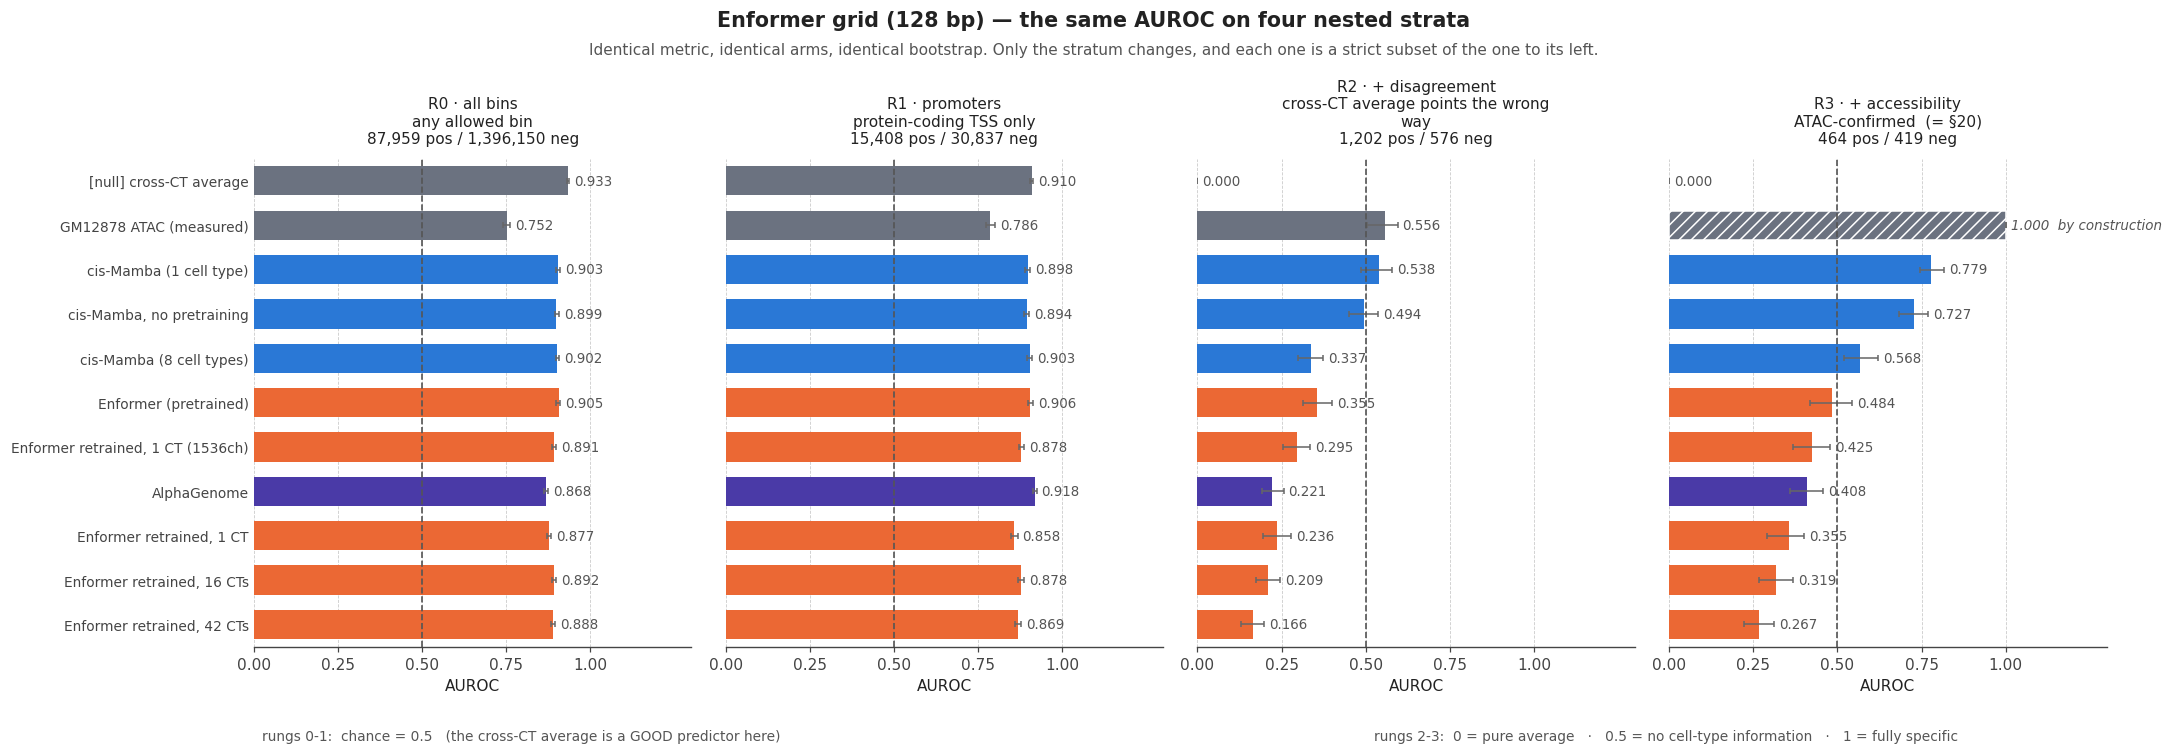

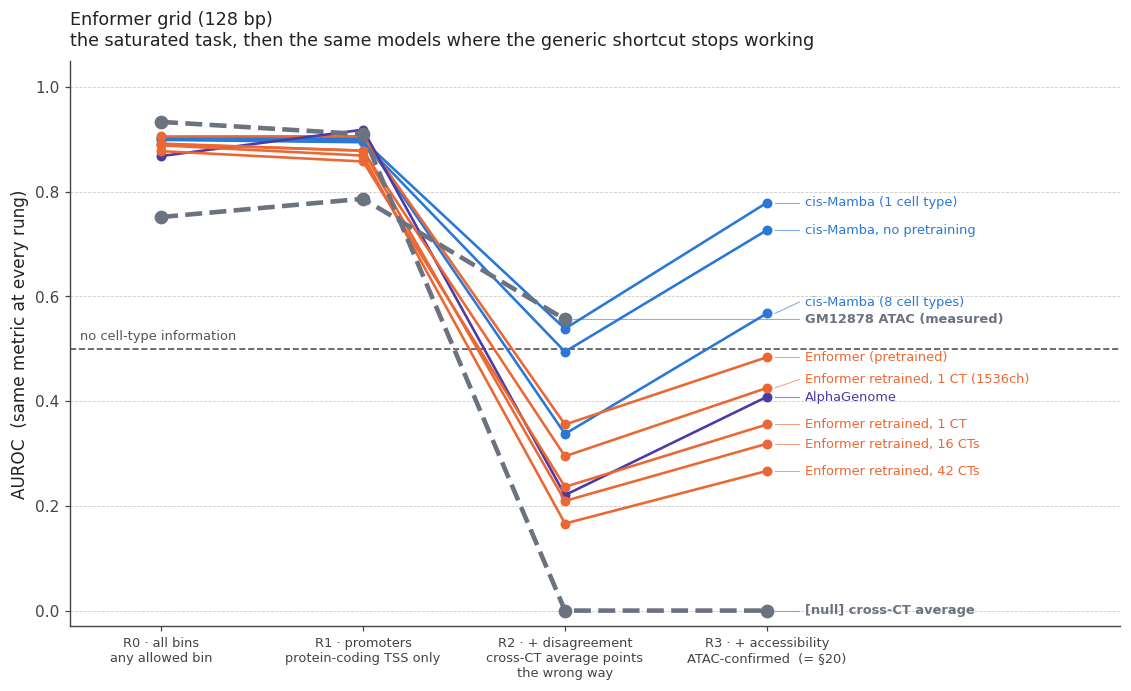

In [3]:
# ============================================================================
# §1b - the Enformer-grid ladder, two views. Nothing is written to disk.
# ============================================================================
fig = fig_ladder_bars(E_LAD, E_RUNGS,
                      'Enformer grid (128 bp) — the same AUROC on four nested strata')
plt.show()

fig = fig_ladder_traj(E_LAD, E_RUNGS, 'Enformer grid (128 bp)')
plt.show()

---
## 2. The Borzoi fold3 grid — 32 bp bins, a genuinely held-out fold, DNase as the orthogonal assay

The same ladder on the better of the two grids: fold3 is properly held out, the resolution is 4x
finer, and the leave-GM12878-out average is cached rather than reconstructed. Loading, the
blacklist, the strand-matched TSS mask and the DNase row-order gate are ported from
`comparing_model5` §1 and §12.

Arms are loaded **one at a time** and released after scoring — the seven fold3 prediction arrays
are ~340 MB each, and the ladder never needs more than one of them resident.

Same two reproduction gates: rung 3 against §12, rung 2 against §12b.

> `AlphaGenome` predicts in its own units (~5x the target's total signal, not Borzoi squashed
> counts). AUROC is rank-based, so every number it gets here is safe — unlike the per-region
> correlations in `comparing_model5` §6/§10, which are not.

In [4]:
# ============================================================================
# §2 - Borzoi fold3 grid. Load + gate + build the four rungs + score.
# Loading is comparing_model5 §1 / §12, unchanged apart from lazy per-arm loading.
# ============================================================================
import json
import os

import numpy as np
import pandas as pd
import zarr
from scipy.stats import pearsonr

BORZOI = '/data1/lesliec/sarthak/data/borzoi'
B_MO = f'{BORZOI}/model_outputs'
JP = '/data1/lesliec/sarthak/data/joint_playground/model_out'
B_BED = '/data1/lesliec/sarthak/data/DK_zarr/sequences_borzoi_fold3-4.bed'

N_REG, N_BIN, BIN_BP = 6888, 6144, 32
SEQ_LEN, TGT_SPAN = 524288, 196608
STRANDS = ('plus', 'minus')
GM_SLOT = 435
B_ACTIVE, B_SILENT, B_TSSPAD = 0.50, 0.05, 500   # §1.5: 50 reads real, <5 reads noise
B_DECIM = 10                                     # R0 is ~74M bins; 1-in-10, unbiased for AUROC

# key, path, layout, poster label, family
B_ARMS_DEF = [
    ('cad_ep4',        f'{JP}/borzoi_gm12878_cage_ep4_outputs.npy',  'h1w2',
     'cis-Mamba (ep4)',                'ours'),
    ('cad_ep10',       f'{JP}/borzoi_gm12878_cage_ep10_outputs.npy', 'h1w2',
     'cis-Mamba (ep10)',               'ours'),
    ('borzoi_trunk',   f'{B_MO}/borzoi_finetuned_gm12878_trunk.npy', 'hw3',
     'Borzoi full FT (GM12878)',       'borzoi'),
    ('borzoi_scratch', f'{B_MO}/borzoi_finetuned_gm12878_scratch.npy', 'hw3',
     'Borzoi from scratch (GM12878)',  'borzoi'),
    ('borzoi_lora',    f'{B_MO}/borzoi_finetuned_gm12878_lorav2.npy', 'hw3',
     'Borzoi LoRA (GM12878)',          'borzoi'),
    ('alphagenome',    f'{JP}/alphagenome_cage_gm12878_borzoi_fold3_32bp.npy', 'hw2',
     'AlphaGenome',                    'alphagenome'),
    ('borzoi_pre',     f'{BORZOI}/model_outputs_fold3_gm12878CAGE.npy', 'hw2',
     'Borzoi (pretrained)',            'borzoi'),
]
_missing = [p for _, p, _, _, _ in B_ARMS_DEF if not os.path.exists(p)]
assert not _missing, 'prediction files not on disk:\n  ' + '\n  '.join(_missing)


def load_arm_flat(path, layout):
    """-> flat float32 of length 2*N_REG*N_BIN, plus strand then minus. Channel 2 (DNase)
    is never read. Same layout handling as comparing_model5 §1 load_arm()."""
    a = np.load(path, mmap_mode='r')
    if layout == 'h1w2':          # caduceus writes (N, 1, T, 2)
        a = a[:, 0]
    return np.concatenate([np.asarray(a[:, :, 0], dtype=np.float32).ravel(),
                           np.asarray(a[:, :, 1], dtype=np.float32).ravel()])


# --- observed target ---------------------------------------------------------
_g = zarr.open(f'{BORZOI}/GM12878CAGE.zarr', mode='r')['fold3']
assert _g.shape == (N_REG, N_BIN, 2), f'unexpected target shape {_g.shape}'
_gt = np.asarray(_g[:], dtype=np.float32)
B_TV = np.concatenate([_gt[:, :, 0].ravel(), _gt[:, :, 1].ravel()])
print(f'target {N_REG} x {N_BIN} x 2 loaded, mean {B_TV.mean():.6f}')

# --- cross-cell-type averages (precomputed by evals/borzoi_cage_avg.py) ------
_a = np.load(f'{BORZOI}/borzoi_fold3_CAGE_avg.npz')
B_AV = np.concatenate([_a['avg_plus_loo'].ravel(), _a['avg_minus_loo'].ravel()])
_meta = json.loads(str(_a['meta']))
assert _meta['gm_slot'] == GM_SLOT
assert _a['cols_plus'][GM_SLOT] == 870 and _a['cols_minus'][GM_SLOT] == 871
print(f"AVG over {_meta['n_cell_types']} cell types; leave-GM12878-out companion present")
del _a, _gt

# --- gate 1: the caduceus arms' own targets are bit-identical to the zarr ----
for _ep in (4, 10):
    _tc = np.load(f'{JP}/borzoi_gm12878_cage_ep{_ep}_targets.npy', mmap_mode='r')[:, 0]
    _flat = np.concatenate([np.asarray(_tc[:, :, 0], dtype=np.float32).ravel(),
                            np.asarray(_tc[:, :, 1], dtype=np.float32).ravel()])
    assert np.array_equal(_flat, B_TV), f'GATE FAILED: ep{_ep} targets differ from the zarr'
    del _flat, _tc
print('gate 1: caduceus ep4/ep10 targets are bit-identical to GM12878CAGE.zarr, both strands')

# --- blacklist: fold3 input context reaching into a training window ----------
bed = pd.read_csv(B_BED, sep='\t', header=None,
                  names=['chrom', 'start', 'end', 'split', 'fold', 'idx'])
assert (bed.end - bed.start).nunique() == 1 and (bed.end - bed.start).iloc[0] == TGT_SPAN
test_bed = bed[bed.fold == 'fold3'].reset_index(drop=True)
assert len(test_bed) == N_REG, f'{len(test_bed)} fold3 rows, expected {N_REG}'
train_bed = bed[~bed.fold.isin(['fold3', 'fold4'])]
PAD = (SEQ_LEN - TGT_SPAN) // 2
blacklisted = np.zeros(N_REG, dtype=bool)
label_overlap = np.zeros(N_REG, dtype=bool)
for chrom, g in train_bed.groupby('chrom'):
    ts, te = g.start.to_numpy(), g.end.to_numpy()
    sel = np.flatnonzero((test_bed.chrom == chrom).to_numpy())
    for i in sel:
        c, d = int(test_bed.start[i]), int(test_bed.end[i])
        if np.maximum(0, np.minimum(te, d + PAD) - np.maximum(ts, c - PAD)).max() > 0.20 * TGT_SPAN:
            blacklisted[i] = True
        if np.maximum(0, np.minimum(te, d) - np.maximum(ts, c)).max() > 0:
            label_overlap[i] = True
allowed = ~blacklisted
assert label_overlap.sum() == 0, (
    f'GATE FAILED: {label_overlap.sum()} fold3 TARGET spans overlap a training target span')
print(f'blacklist: {blacklisted.sum()} / {N_REG} regions dropped -> {allowed.sum()} allowed; '
      f'0 target-span overlaps (no label leakage)')

# --- DNase on the fold3 grid, with the row-order and tracking checks ---------
B_DN = np.load(f'{BORZOI}/GM12878DNase.npz')['test'][:, :, 0]
assert B_DN.shape == (N_REG, N_BIN), f'DNase is {B_DN.shape}, expected {(N_REG, N_BIN)}'
_wi = pd.read_csv(f'{BORZOI}/GM12878_borzoi_window_index.tsv', sep='\t', dtype={'chrom': str})
_wt = _wi[_wi.npz_split == 'test'].reset_index(drop=True)
assert len(_wt) == N_REG and (_wt.start.to_numpy() == test_bed.start.to_numpy()).all() \
    and (_wt.chrom.astype(str).to_numpy() == test_bed.chrom.astype(str).to_numpy()).all(), \
    'GATE FAILED: the DNase npz row order is not the bed fold3 row order'
_tp = B_TV[:N_REG * N_BIN].reshape(N_REG, N_BIN)
_r_ok = pearsonr(np.log1p(B_DN[:1200]).ravel(), np.log1p(_tp[:1200]).ravel())[0]
_perm = np.random.default_rng(0).permutation(1200)
_r_ctl = pearsonr(np.log1p(B_DN[_perm]).ravel(), np.log1p(_tp[:1200]).ravel())[0]
assert _r_ok > 0.15 and _r_ok > 5 * abs(_r_ctl), 'DNase does not track CAGE'
print(f'DNase gate: row order matches fold3; DNase vs CAGE(+) r={_r_ok:+.3f}, '
      f'region-shuffled control r={_r_ctl:+.3f}')
del _tp

# --- strand-matched protein-coding TSS mask on the 32 bp grid ----------------
_pc = GeneAnnotation(gene_types=('protein_coding',)).df
_pc = _pc[_pc['feature'] == 'transcript']
_ctr = (test_bed.start.to_numpy().astype(np.int64)[:, None]
        + np.arange(N_BIN)[None, :] * BIN_BP + BIN_BP // 2)
_chr = test_bed.chrom.to_numpy().astype(str)
_tss = []
for _s, _st in zip(STRANDS, ('+', '-')):
    _d = {}
    for _ch, _g in _pc[_pc['strand'] == _st].groupby('chrom'):
        _p = np.where(_st == '+', _g['start0'].to_numpy(), _g['end0'].to_numpy())
        _d[str(_ch)] = np.sort(_p)
    _m = np.zeros((N_REG, N_BIN), bool)
    for _ch in np.unique(_chr):
        _arr = _d.get(_ch)
        if _arr is None or _arr.size == 0:
            continue
        _rows = np.flatnonzero(_chr == _ch); _c = _ctr[_rows]
        _i = np.searchsorted(_arr, _c)
        _lo = _arr[np.clip(_i - 1, 0, _arr.size - 1)]
        _hi = _arr[np.clip(_i, 0, _arr.size - 1)]
        _m[_rows] = np.minimum(np.abs(_c - _lo), np.abs(_c - _hi)) <= B_TSSPAD
    print(f'  {_s}: {_m[allowed].mean():.2%} of allowed bins within {B_TSSPAD} bp '
          f'of a {_st} protein-coding TSS')
    _tss.append(_m.ravel())
B_TS = np.concatenate(_tss)
del _tss, _m

# ============================================================================
# THE LADDER, identical in construction to the Enformer grid's.
# ============================================================================
B_A = np.concatenate([np.repeat(allowed, N_BIN)] * 2)
B_RID = np.concatenate([np.repeat(np.arange(N_REG), N_BIN)] * 2)
B_DNF = np.concatenate([B_DN.ravel()] * 2)                 # DNase is unstranded
B_OPEN = float(np.percentile(B_DNF[B_A], 95))
_hi_avg = B_AV >= np.percentile(B_AV[B_A & B_TS], 90)
_lo_avg = B_AV < np.percentile(B_AV[B_A & B_TS], 50)

_keep = np.zeros_like(B_A)
_keep[::B_DECIM] = True

B_R0_POS = B_A & (B_TV >= B_ACTIVE) & _keep
B_R0_NEG = B_A & (B_TV <  B_SILENT) & _keep
B_R1_POS = B_A & B_TS & (B_TV >= B_ACTIVE)
B_R1_NEG = B_A & B_TS & (B_TV <  B_SILENT)
B_R2_POS = B_R1_POS & _lo_avg                              # == §12b
B_R2_NEG = B_R1_NEG & _hi_avg
B_R3_POS = B_R2_POS & (B_DNF >= B_OPEN)                    # == §12
B_R3_NEG = B_R2_NEG & (B_DNF <  B_OPEN)

B_RUNGS = [
    make_rung('R0 · all bins', f'any allowed bin, 1-in-{B_DECIM} subsample',
              B_R0_POS, B_R0_NEG, B_RID),
    make_rung('R1 · promoters', 'protein-coding TSS only', B_R1_POS, B_R1_NEG, B_RID),
    make_rung('R2 · + disagreement', 'cross-CT average points the wrong way',
              B_R2_POS, B_R2_NEG, B_RID),
    make_rung('R3 · + accessibility', 'DNase-confirmed  (= §12)', B_R3_POS, B_R3_NEG, B_RID),
]
print(f'\n"open" = DNase >= p95 of allowed bins = {B_OPEN:.3f}')
print(f"{'rung':<24}{'positives':>12}{'negatives':>12}{'pos regions':>14}{'neg regions':>13}")
for r in B_RUNGS:
    print(f"{r['name']:<24}{r['n_pos']:>12,}{r['n_neg']:>12,}{r['n_preg']:>14,}{r['n_nreg']:>13,}")

_L = lambda x: np.log1p(np.clip(x, 0, None))
_pool = np.flatnonzero(B_A & (B_TV >= B_ACTIVE))
_sub = np.random.default_rng(0).choice(_pool, min(300_000, len(_pool)), replace=False)
B_RTA = float(np.corrcoef(_L(B_TV[_sub]), _L(B_AV[_sub]))[0, 1])
_p50 = np.percentile(B_AV[B_A & B_TS], 50)
_p90 = np.percentile(B_AV[B_A & B_TS], 90)
print(f'\nr(TRUE, AVG_LOO) = {B_RTA:.3f} over {len(_sub):,} sampled active bins')
print(f'of the {B_R1_POS.sum():,} promoter bins active in GM12878, '
      f'{np.mean(B_AV[B_R1_POS] >= _p50):.1%} are ALSO generically active (AVG >= p50) '
      f'and {np.mean(B_AV[B_R1_POS] >= _p90):.1%} are in the generic top decile')
print(f'   -> only {B_R3_POS.sum() / B_R1_POS.sum():.1%} of them survive into rung 3.')

# ============================================================================
# Same two reference arms as the Enformer grid; DNase defines the R3 classes here.
B_ACC_LABEL = 'GM12878 DNase (measured)'
B_ARMS = [(k, lab, fam, (lambda p=path, l=layout: load_arm_flat(p, l)))
          for k, path, layout, lab, fam in B_ARMS_DEF]
B_ARMS.append(('__avg__', '[null] cross-CT average', 'reference', lambda: B_AV))
B_ARMS.append(('__acc__', B_ACC_LABEL, 'reference', lambda: B_DNF))
print('\nscoring the ladder (one arm resident at a time) ...')
B_LAD = score_ladder(B_ARMS, B_RUNGS)
B_LAD['by_construction'] = ((B_LAD.label == B_ACC_LABEL)
                            & (B_LAD.rung == B_RUNGS[3]['name']))
assert float(B_LAD[B_LAD.by_construction].auroc.iloc[0]) == 1.0, \
    'DNase does not perfectly separate the R3 classes -- it should, since it defines them'

# --- gate: rung 3 must reproduce §12, rung 2 must reproduce §12b -------------
B_PUB_R3 = {'cis-Mamba (ep4)': 0.626, 'cis-Mamba (ep10)': 0.578,
            'Borzoi full FT (GM12878)': 0.462, 'Borzoi from scratch (GM12878)': 0.436,
            'Borzoi LoRA (GM12878)': 0.395, 'AlphaGenome': 0.348,
            'Borzoi (pretrained)': 0.177, '[null] cross-CT average': 0.000}
B_PUB_R2 = {'cis-Mamba (ep4)': 0.354, 'cis-Mamba (ep10)': 0.329,
            'Borzoi full FT (GM12878)': 0.300, 'Borzoi from scratch (GM12878)': 0.238,
            'Borzoi LoRA (GM12878)': 0.231, 'AlphaGenome': 0.179,
            'Borzoi (pretrained)': 0.092}
for _rung, _pub, _src in ((B_RUNGS[3]['name'], B_PUB_R3, 'comparing_model5 §12'),
                          (B_RUNGS[2]['name'], B_PUB_R2, 'comparing_model5 §12b')):
    _got = B_LAD[B_LAD.rung == _rung].set_index('label').auroc
    _bad = {k: (v, float(_got[k])) for k, v in _pub.items() if abs(_got[k] - v) > 2e-3}
    assert not _bad, f'GATE FAILED [{_src}]: {_bad}'
    print(f'gate: {_rung} reproduces {_src} for all {len(_pub)} arms (tol 0.002)')

B_WIDE = B_LAD.pivot(index='label', columns='rung', values='auroc')[
    [r['name'] for r in B_RUNGS]].sort_values(B_RUNGS[3]['name'], ascending=False)
print(f'\naccessibility baseline: measured DNase scores '
      + ', '.join(f"{r['name'].split(chr(183))[0].strip()} "
                  f"{float(B_LAD[(B_LAD.label == B_ACC_LABEL) & (B_LAD.rung == r['name'])].auroc.iloc[0]):.3f}"
                  for r in B_RUNGS)
      + '   (R3 = 1.000 by construction)')
print('\nBORZOI FOLD3 GRID - AUROC across the ladder')
print(f"{'arm':<34}" + ''.join(f'{r["name"].split(chr(183))[0].strip():>10}' for r in B_RUNGS)
      + f"{'R1 - R3':>10}")
for _lab, _row in B_WIDE.iterrows():
    print(f'{_lab:<34}' + ''.join(f'{v:>10.3f}' for v in _row.values)
          + f'{_row.values[1] - _row.values[3]:>10.3f}')

target 6888 x 6144 x 2 loaded, mean 0.059020


AVG over 638 cell types; leave-GM12878-out companion present


gate 1: caduceus ep4/ep10 targets are bit-identical to GM12878CAGE.zarr, both strands
blacklist: 91 / 6888 regions dropped -> 6797 allowed; 0 target-span overlaps (no label leakage)


DNase gate: row order matches fold3; DNase vs CAGE(+) r=+0.220, region-shuffled control r=-0.002


  plus: 1.15% of allowed bins within 500 bp of a + protein-coding TSS


...

  scored Borzoi LoRA (GM12878)


  scored AlphaGenome


  scored Borzoi (pretrained)


  scored [null] cross-CT average


  scored GM12878 DNase (measured)
gate: R3 · + accessibility reproduces comparing_model5 §12 for all 8 arms (tol 0.002)
gate: R2 · + disagreement reproduces comparing_model5 §12b for all 7 arms (tol 0.002)

accessibility baseline: measured DNase scores R0 0.673, R1 0.736, R2 0.389, R3 1.000   (R3 = 1.000 by construction)

BORZOI FOLD3 GRID - AUROC across the ladder
arm                                       R0        R1        R2        R3   R1 - R3
GM12878 DNase (measured)               0.673     0.736     0.389     1.000    -0.264
cis-Mamba (ep4)                        0.890     0.887     0.354     0.626     0.261
cis-Mamba (ep10)                       0.892     0.886     0.329     0.578     0.309
Borzoi full FT (GM12878)               0.892     0.897     0.300     0.462     0.436
Borzoi from scratch (GM12878)          0.878     0.864     0.238     0.436     0.428
Borzoi LoRA (GM12878)                  0.894     0.896     0.231     0.395     0.501
AlphaGenome                          

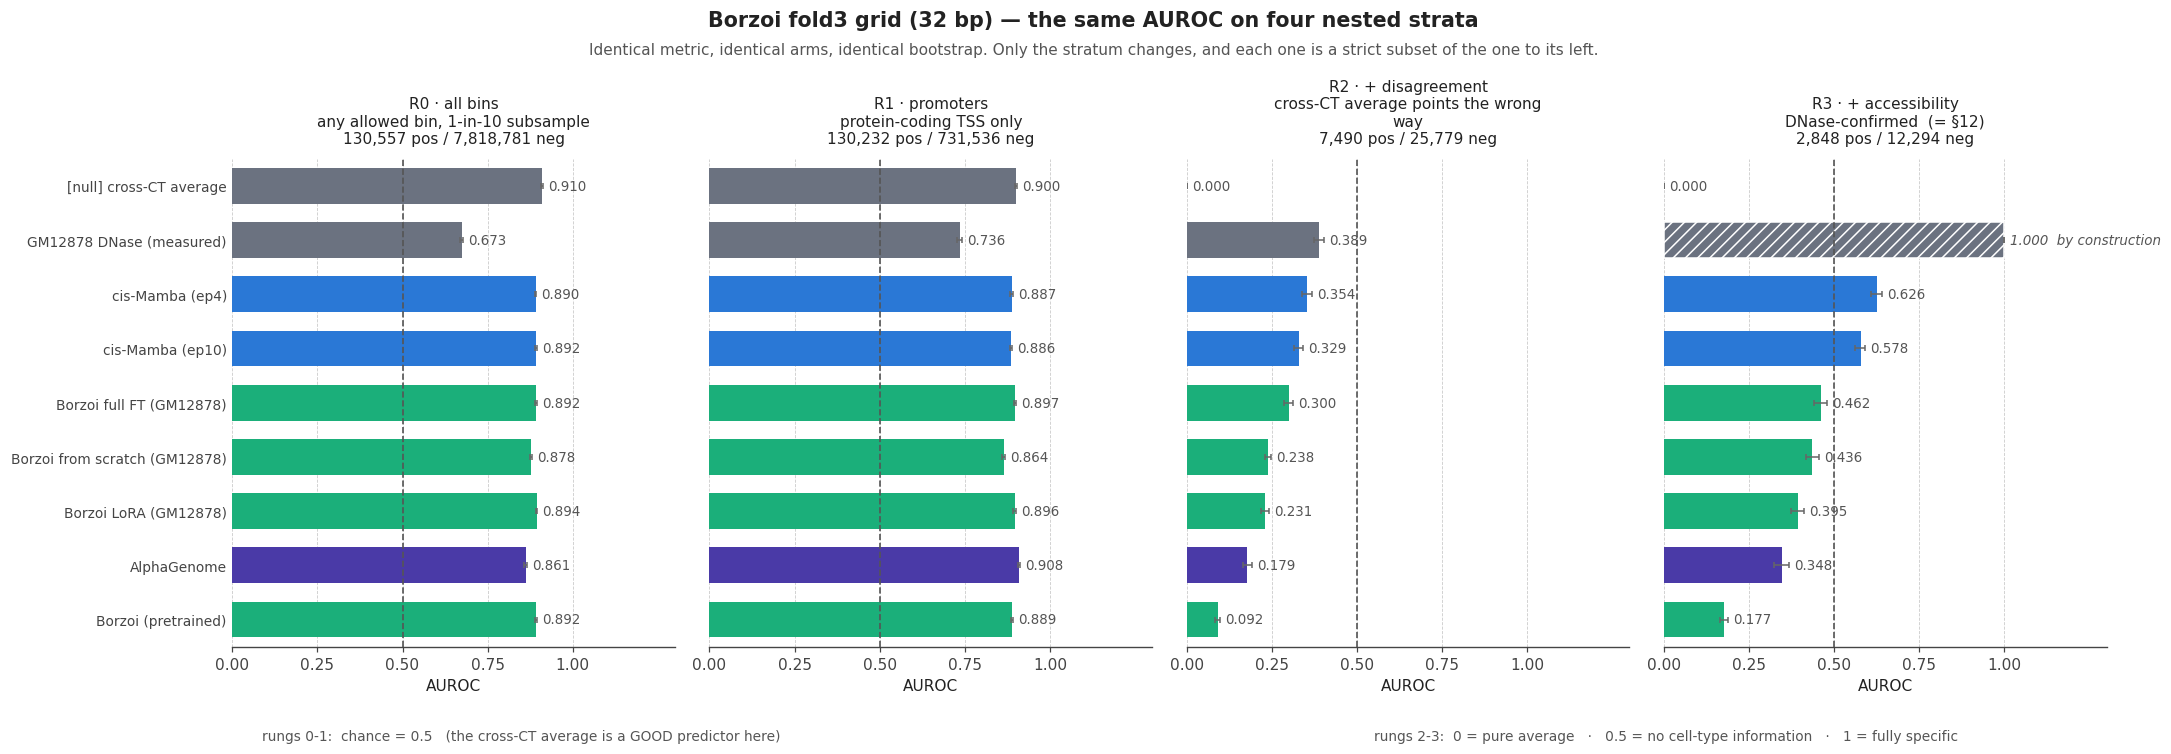

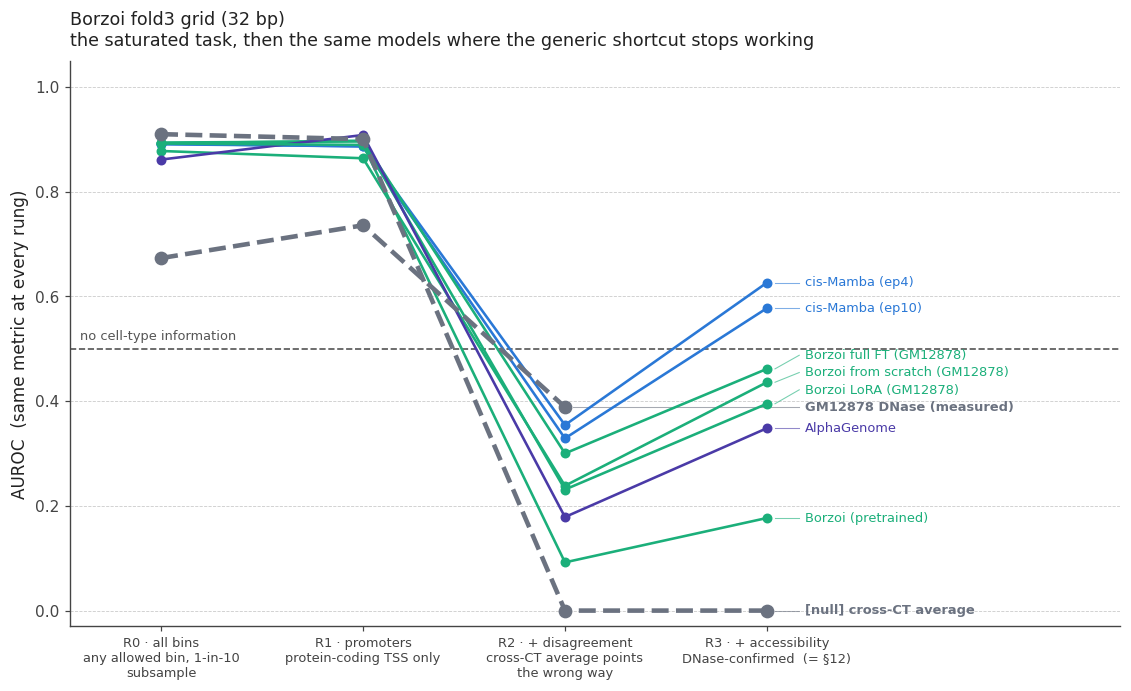

In [5]:
# ============================================================================
# §2b - the Borzoi-grid ladder, two views. Nothing is written to disk.
# ============================================================================
fig = fig_ladder_bars(B_LAD, B_RUNGS,
                      'Borzoi fold3 grid (32 bp) — the same AUROC on four nested strata')
plt.show()

fig = fig_ladder_traj(B_LAD, B_RUNGS, 'Borzoi fold3 grid (32 bp)')
plt.show()

In [6]:
# ============================================================================
# §3 - the sentences, computed rather than typed. Every number below is read out
# of E_LAD / B_LAD, so the prose cannot drift from the tables above it.
# ============================================================================
def summarise(lad, rungs, grid, r_ta, acc_label):
    d = lad.pivot(index='label', columns='rung', values='auroc')[[r['name'] for r in rungs]]
    refs = lad[lad.family == 'reference'].label.unique()
    models = d.drop(index=list(refs))
    null = d.loc['[null] cross-CT average']
    acc = d.loc[acc_label]
    r0, r1, r2, r3 = [r['name'] for r in rungs]
    print(f'--- {grid} ---')
    print(f'  R1 (all promoters, saturated task): models span '
          f'{models[r1].min():.3f}-{models[r1].max():.3f}  '
          f'(span {models[r1].max() - models[r1].min():.3f}); '
          f'the cross-CT average null scores {null[r1]:.3f}')
    print(f'  R3 (the specificity contrast):      models span '
          f'{models[r3].min():.3f}-{models[r3].max():.3f}  '
          f'(span {models[r3].max() - models[r3].min():.3f}); '
          f'the null scores {null[r3]:.3f} by construction')
    print(f'  the null moves {null[r1]:.3f} -> {null[r3]:.3f}: the ruler did not change, '
          f'the stratum did')
    print(f'  arms below 0.5 at R3: {int((models[r3] < 0.5).sum())} / {len(models)}   '
          f'|  at R1: {int((models[r1] < 0.5).sum())} / {len(models)}')
    print(f'  largest R1 -> R3 drop: {(models[r1] - models[r3]).idxmax()} '
          f'{(models[r1] - models[r3]).max():+.3f}   '
          f'smallest: {(models[r1] - models[r3]).idxmin()} '
          f'{(models[r1] - models[r3]).min():+.3f}')
    print(f'  {acc_label}: R0 {acc[r0]:.3f}  R1 {acc[r1]:.3f}  R2 {acc[r2]:.3f}  '
          f'(R3 {acc[r3]:.3f} by construction).  At R2 it beats '
          f'{int((models[r2] < acc[r2]).sum())} / {len(models)} models -- the measurement of '
          f'this cell type is a harder baseline than most sequence models.')
    print(f'  r(TRUE, AVG_LOO) over active bins = {r_ta:.3f}')
    print()


summarise(E_LAD, E_RUNGS, 'Enformer grid (128 bp)', E_RTA, E_ACC_LABEL)
summarise(B_LAD, B_RUNGS, 'Borzoi fold3 grid (32 bp)', B_RTA, B_ACC_LABEL)

print('The claim these two tables support, in the order a reader meets it:')
print('  1. On the task the field reports, every arm is near ceiling and the cross-cell-type')
print('     average is one of the best predictors on the board. The task is saturated.')
print('  2. Restrict to promoters where the generic expectation points the wrong way -- same')
print('     metric, same arms, same bootstrap, strictly fewer bins -- and the ordering changes')
print('     completely, with most arms falling below "no cell-type information".')
print('  3. The null falls with them, all the way to 0. That is what tells you the second')
print('     panel is measuring reliance on the generic shortcut and not task difficulty.')

--- Enformer grid (128 bp) ---
  R1 (all promoters, saturated task): models span 0.858-0.918  (span 0.061); the cross-CT average null scores 0.910
  R3 (the specificity contrast):      models span 0.267-0.779  (span 0.512); the null scores 0.000 by construction
  the null moves 0.910 -> 0.000: the ruler did not change, the stratum did
  arms below 0.5 at R3: 6 / 9   |  at R1: 0 / 9
  largest R1 -> R3 drop: Enformer retrained, 42 CTs +0.602   smallest: cis-Mamba (1 cell type) +0.119
  GM12878 ATAC (measured): R0 0.752  R1 0.786  R2 0.556  (R3 1.000 by construction).  At R2 it beats 9 / 9 models -- the measurement of this cell type is a harder baseline than most sequence models.
  r(TRUE, AVG_LOO) over active bins = 0.803

--- Borzoi fold3 grid (32 bp) ---
  R1 (all promoters, saturated task): models span 0.864-0.908  (span 0.044); the cross-CT average null scores 0.900
  R3 (the specificity contrast):      models span 0.177-0.626  (span 0.449); the null scores 0.000 by construction
  th

---
## 4. The sensitivity sweep — is the finding a property of the data or of the thresholds?

Rungs 2 and 3 depend on three chosen numbers: the noise floor (what counts as active / silent),
the cross-cell-type-average quantiles (how far apart "generic" and "specific" have to be), and the
accessibility percentile (what counts as open). Each was set once, for reasons recorded in §2.5 /
§1.5 and §20 / §12 — but "set once, for a reason" is not the same as "does not matter."

This section turns each knob **one at a time**, holding the other two at their nominal value, and
rescores every arm. Three settings per knob, so seven distinct configurations per rung.

| knob | settings | what it controls |
|---|---|---|
| noise floor | active/silent × **0.5**, **1** (nominal), **2** | how confidently on / off a bin has to be |
| disagreement cut | avg quantiles **(p60, p80)**, **(p50, p90)** (nominal), **(p40, p95)** | how hard the contrast is |
| open threshold | accessibility **p90**, **p95** (nominal), **p99** | how strict the orthogonal assay is (R3 only) |

**The claim under test is not the numbers, it is the ordering.** Individual AUROCs will move — a
harder contrast is a harder contrast. What must not move is which arms lead, and whether the
sub-0.5 finding survives. Each panel prints the Spearman rank correlation of the arm ordering
against the nominal setting, and the count of arms below 0.5.

Two structural facts to expect, both of which are checks rather than results:

* **The null sits at exactly 0.000 at every setting of every knob.** The positive and negative
  average-quantile cuts stay disjoint with a gap under all three settings, so a pure
  average-predictor ranks every negative above every positive regardless. If the null ever moved
  off 0, a knob would have broken the contrast's construction.
* **The accessibility baseline is flat at 1.000 across the R3 row** — it defines those classes.
  It is informative on the R2 row, where it does not.

The open-threshold knob does not enter R2 at all (R2's classes never touch the assay), so that
panel is left empty on the R2 row rather than plotting a flat line and implying a null result.

In [7]:
# ============================================================================
# §4 - the sweep engine. Reuses make_rung / score_rung / to_codes unchanged, so a
# swept point and a nominal point are computed by the same code path; only the
# masks differ. Point estimates only (n_boot=0) -- the question here is whether the
# ORDERING moves, and the intervals at the nominal setting are already in §1/§2.
# ============================================================================
from scipy.stats import spearmanr

SWEEP_NOMINAL = dict(scale=1.0, lo_p=50, hi_p=90, open_p=95)

KNOBS = [
    dict(name='noise floor', axis='active / silent thresholds',
         settings=[('x0.5', dict(scale=0.5)),
                   ('x1  (nominal)', dict(scale=1.0)),
                   ('x2', dict(scale=2.0))]),
    dict(name='disagreement cut', axis='cross-CT average quantiles   (pos <  /  neg >=)',
         settings=[('p60 / p80', dict(lo_p=60, hi_p=80)),
                   ('p50 / p90  (nominal)', dict(lo_p=50, hi_p=90)),
                   ('p40 / p95', dict(lo_p=40, hi_p=95))]),
    dict(name='open threshold', axis='"open" percentile of the accessibility assay',
         settings=[('p90', dict(open_p=90)),
                   ('p95  (nominal)', dict(open_p=95)),
                   ('p99', dict(open_p=99))]),
]
R2_KEY, R3_KEY = 'R2 · + disagreement', 'R3 · + accessibility'


def build_sweep(ctx):
    """One-at-a-time sweep: each knob moved with the other two held at nominal."""
    prom = ctx['A'] & ctx['TS']
    _av_cache, _ac_cache = {}, {}

    def pct_av(q):
        if q not in _av_cache:
            _av_cache[q] = float(np.percentile(ctx['av'][prom], q))
        return _av_cache[q]

    def pct_acc(q):
        if q not in _ac_cache:
            _ac_cache[q] = float(np.percentile(ctx['acc'][ctx['A']], q))
        return _ac_cache[q]

    out = []
    for knob in KNOBS:
        for si, (slabel, override) in enumerate(knob['settings']):
            c = dict(SWEEP_NOMINAL, **override)
            p1 = prom & (ctx['tv'] >= ctx['active'] * c['scale'])
            n1 = prom & (ctx['tv'] <  ctx['silent'] * c['scale'])
            p2 = p1 & (ctx['av'] <  pct_av(c['lo_p']))
            n2 = n1 & (ctx['av'] >= pct_av(c['hi_p']))
            op = pct_acc(c['open_p'])
            p3, n3 = p2 & (ctx['acc'] >= op), n2 & (ctx['acc'] < op)
            for rk, pm, nm in ((R2_KEY, p2, n2), (R3_KEY, p3, n3)):
                # the open-threshold knob does not enter R2's class definition
                if knob['name'] == 'open threshold' and rk == R2_KEY:
                    continue
                out.append(dict(knob=knob['name'], setting=slabel, setting_i=si,
                                is_nominal='nominal' in slabel, rung_key=rk,
                                rung=make_rung(rk, slabel, pm, nm, ctx['rid'])))
    return out


def score_sweep(arms, srungs):
    rows = []
    for key, label, family, loader in arms:
        pv = loader()
        for s in srungs:
            a0, _, _ = score_rung(pv, s['rung'], n_boot=0)
            rows.append(dict(key=key, label=label, family=family, knob=s['knob'],
                             setting=s['setting'], setting_i=s['setting_i'],
                             is_nominal=s['is_nominal'], rung_key=s['rung_key'], auroc=a0,
                             n_pos=s['rung']['n_pos'], n_neg=s['rung']['n_neg']))
        del pv
        print(f'  swept {label}')
    return pd.DataFrame(rows)


def sweep_stability(sw, acc_label):
    """Spearman of the model ordering against the nominal setting, per knob and rung."""
    models = sw[(sw.family != 'reference')]
    print(f"{'rung':<22}{'knob':<20}{'setting':<24}{'rho vs nominal':>15}"
          f"{'arms < 0.5':>12}{'pos/neg':>18}")
    for rk in (R2_KEY, R3_KEY):
        for knob in KNOBS:
            d = models[(models.rung_key == rk) & (models.knob == knob['name'])]
            if d.empty:
                continue
            ref = d[d.is_nominal].set_index('label').auroc
            for si in sorted(d.setting_i.unique()):
                g = d[d.setting_i == si].set_index('label')
                rho = spearmanr(ref, g.auroc.loc[ref.index]).statistic
                n = g.iloc[0]
                print(f"{rk.split(chr(183))[0].strip():<22}{knob['name']:<20}"
                      f"{g.setting.iloc[0]:<24}{rho:>15.3f}"
                      f"{int((g.auroc < 0.5).sum()):>7} / {len(g):<3}"
                      f"{f'{n.n_pos:,} / {n.n_neg:,}':>18}")
    print('\n   rho = 1.000 means the knob did not reorder a single arm.')


def _family_markers(df):
    """Colour carries the family, so within a family the marker has to carry identity --
    four Borzoi arms are four identical greens otherwise. Same convention as poster panel H."""
    marks = ['o', 's', 'D', '^', 'v', 'P', 'X']
    out = {}
    for _fam, g in df.groupby('family', sort=False):
        for i, lab in enumerate(dict.fromkeys(g.label)):
            out[lab] = marks[i % len(marks)]
    return out


def fig_sweep(sw, grid_title, acc_label):
    """Two rows (R2, R3) x three knobs. One line per arm; nominal setting shaded."""
    MK = _family_markers(sw)
    fig, axes = plt.subplots(2, len(KNOBS), figsize=(16.5, 9.2), sharey=True)
    for row, rk in enumerate((R2_KEY, R3_KEY)):
        for col, knob in enumerate(KNOBS):
            ax = axes[row, col]
            d = sw[(sw.rung_key == rk) & (sw.knob == knob['name'])]
            if d.empty:
                ax.text(0.5, 0.5, "the open threshold does not\nenter R2's class definition\n"
                        '(R2 never touches the assay)', ha='center', va='center',
                        fontsize=10, color=INK2, style='italic', transform=ax.transAxes)
                ax.axis('off')      # not set_yticks([]): sharey would strip every panel
                continue
            xs = sorted(d.setting_i.unique())
            nom = d[d.is_nominal].setting_i.iloc[0]
            ax.axvspan(nom - 0.18, nom + 0.18, color='#f0f0f0', zorder=0)
            for label, g in d.groupby('label', sort=False):
                g = g.sort_values('setting_i')
                is_ref = g.family.iloc[0] == 'reference'
                by_con = is_ref and label == acc_label and rk == R3_KEY
                ax.plot(g.setting_i, g.auroc, marker=MK[label], ms=6,
                        color=FAMILY[g.family.iloc[0]],
                        lw=2.6 if is_ref else 1.6, ls='--' if is_ref else '-',
                        alpha=0.55 if by_con else 1.0,
                        zorder=4 if is_ref else 3, label=label)
            ax.axhline(0.5, ls='--', lw=1.0, color=INK2, zorder=1)
            ax.set_xticks(xs)
            ax.set_xticklabels([d[d.setting_i == i].setting.iloc[0] for i in xs], fontsize=9)
            ax.set_xlim(-0.4, len(xs) - 0.6)
            ax.set_ylim(-0.03, 1.05)
            ax.set_yticks([0, 0.25, 0.5, 0.75, 1.0])
            ax.grid(axis='y', ls='--', lw=0.55, color='#CCCCCC', zorder=0)
            ax.set_axisbelow(True)
            if row == 1:
                ax.set_xlabel(textwrap.fill(knob['axis'], 44), fontsize=9.5)
            if col == 0:
                ax.set_ylabel(f"{rk}\nAUROC", fontsize=10)
            if row == 0:
                ax.set_title(knob['name'], fontsize=11.5, pad=8)
    h, l = axes[1, 0].get_legend_handles_labels()
    fig.legend(h, l, loc='lower center', ncol=5, frameon=False, fontsize=9,
               bbox_to_anchor=(0.5, -0.10), handletextpad=0.4, columnspacing=1.4)
    fig.text(0.5, 1.035, grid_title + ' — one knob at a time, the other two held nominal',
             ha='center', fontsize=13.5, fontweight='bold', color=INK)
    fig.text(0.5, 0.995, 'The shaded column is the published setting. What must survive is the '
             'ORDERING and the sub-0.5 finding, not the individual values.',
             ha='center', fontsize=10, color=INK2)
    fig.tight_layout()
    return fig


print(f'sweep engine ready: {len(KNOBS)} knobs x 3 settings, one at a time, point estimates only')

sweep engine ready: 3 knobs x 3 settings, one at a time, point estimates only


15 swept (config, rung) pairs; scoring ...
  swept cis-Mamba (1 cell type)
  swept cis-Mamba, no pretraining
  swept cis-Mamba (8 cell types)
  swept Enformer (pretrained)
  swept AlphaGenome
  swept Enformer retrained, 1 CT
  swept Enformer retrained, 1 CT (1536ch)
  swept Enformer retrained, 16 CTs
  swept Enformer retrained, 42 CTs
  swept [null] cross-CT average
  swept GM12878 ATAC (measured)

gate: the null is 0.000 at all 15 swept points; ATAC is 1.000 at all 9 R3 points
rung                  knob                setting                  rho vs nominal  arms < 0.5           pos/neg
R2                    noise floor         x0.5                              0.983      8 / 9         2,936 / 463
R2                    noise floor         x1  (nominal)                     1.000      8 / 9         1,202 / 576
R2                    noise floor         x2                                0.933      7 / 9           274 / 709
R2                    disagreement cut    p60 / p80               

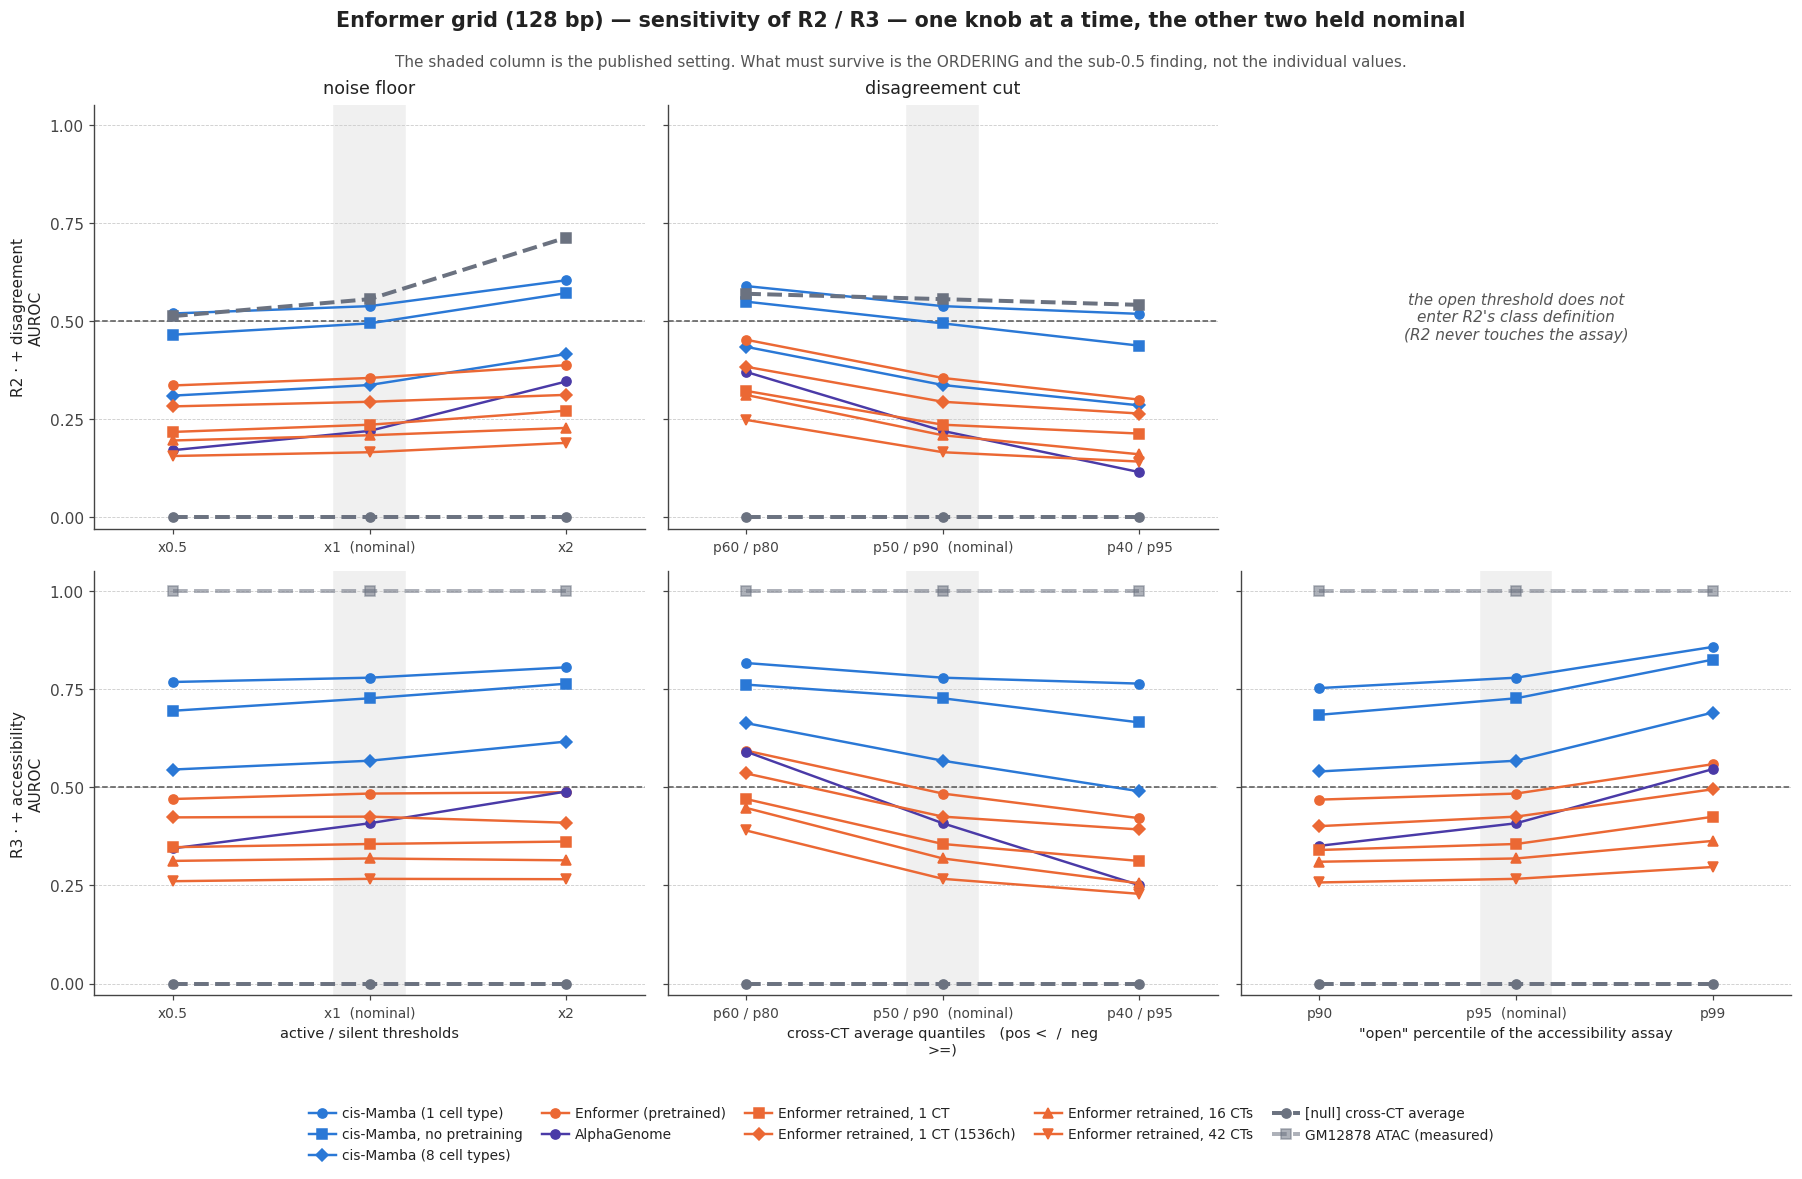

In [8]:
# ============================================================================
# §4a - the sweep on the Enformer grid.
# ============================================================================
E_CTX = dict(A=E_A, TS=E_TSS.ravel(), tv=E_TRUE.ravel(), av=E_AVG.ravel(),
             acc=E_ATAC.ravel(), rid=E_RID, active=E_ACTIVE, silent=E_SILENT)
E_SW_RUNGS = build_sweep(E_CTX)
print(f'{len(E_SW_RUNGS)} swept (config, rung) pairs; scoring ...')
E_SW = score_sweep(E_ARMS, E_SW_RUNGS)

# the two structural checks the sweep is supposed to satisfy
_null = E_SW[E_SW.label == '[null] cross-CT average']
assert (_null.auroc.abs() < 1e-12).all(), \
    'GATE FAILED: the null left 0.0 under some setting -- a knob broke the contrast'
_acc3 = E_SW[(E_SW.label == E_ACC_LABEL) & (E_SW.rung_key == R3_KEY)]
assert np.allclose(_acc3.auroc, 1.0), 'GATE FAILED: ATAC no longer defines the R3 classes'
print(f'\ngate: the null is 0.000 at all {len(_null)} swept points; '
      f'ATAC is 1.000 at all {len(_acc3)} R3 points')

sweep_stability(E_SW, E_ACC_LABEL)
fig = fig_sweep(E_SW, 'Enformer grid (128 bp) — sensitivity of R2 / R3', E_ACC_LABEL)
plt.show()

15 swept (config, rung) pairs; scoring ...


  swept cis-Mamba (ep4)


  swept cis-Mamba (ep10)


  swept Borzoi full FT (GM12878)


  swept Borzoi from scratch (GM12878)


  swept Borzoi LoRA (GM12878)


  swept AlphaGenome


  swept Borzoi (pretrained)
  swept [null] cross-CT average
  swept GM12878 DNase (measured)

gate: the null is 0.000 at all 15 swept points; DNase is 1.000 at all 9 R3 points
rung                  knob                setting                  rho vs nominal  arms < 0.5           pos/neg
R2                    noise floor         x0.5                              1.000      7 / 7     10,766 / 24,634
R2                    noise floor         x1  (nominal)                     1.000      7 / 7      7,490 / 25,779
R2                    noise floor         x2                                0.964      7 / 7      3,109 / 27,466
R2                    disagreement cut    p60 / p80                         0.964      7 / 7     12,543 / 73,957
R2                    disagreement cut    p50 / p90  (nominal)              1.000      7 / 7      7,490 / 25,779
R2                    disagreement cut    p40 / p95                         1.000      7 / 7       4,316 / 9,128
R3                    noise floor 

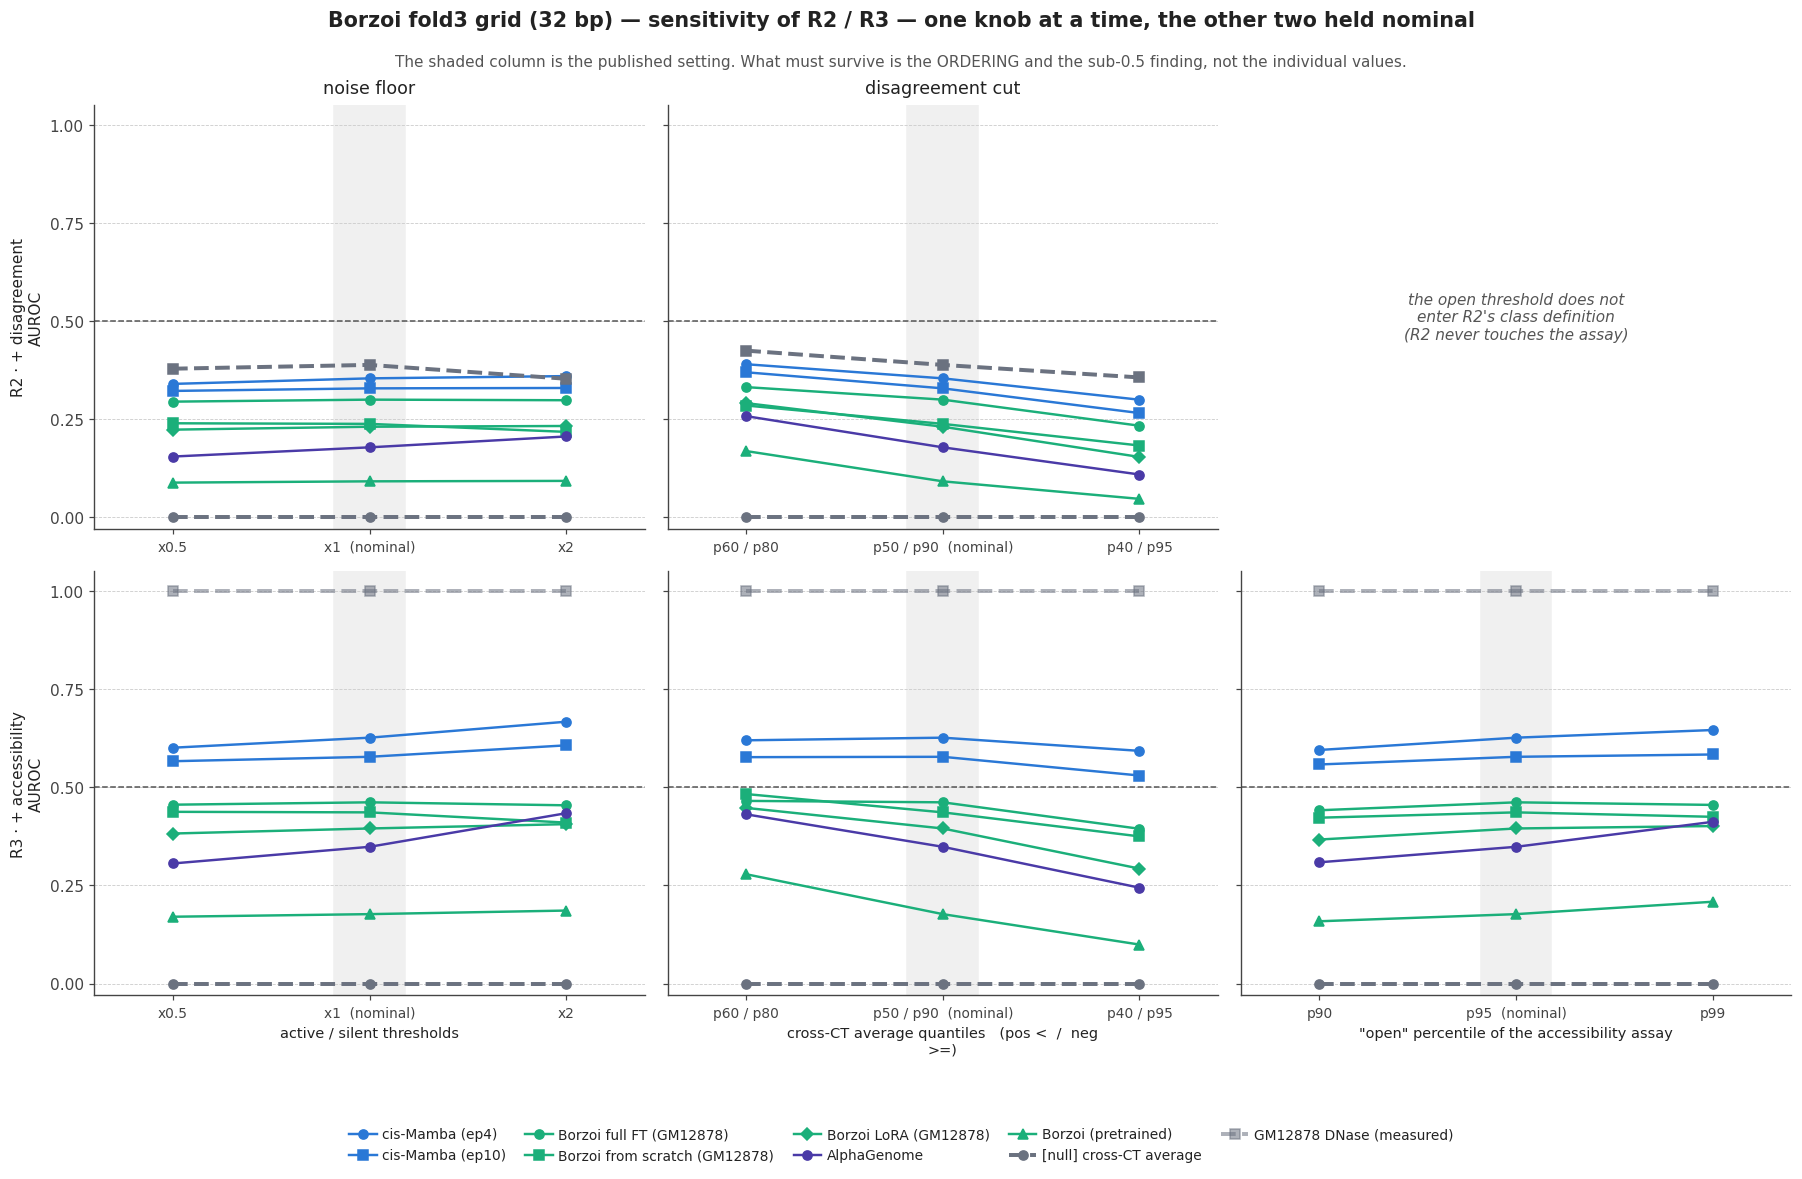

In [9]:
# ============================================================================
# §4b - the same sweep on the Borzoi fold3 grid.
# ============================================================================
B_CTX = dict(A=B_A, TS=B_TS, tv=B_TV, av=B_AV, acc=B_DNF, rid=B_RID,
             active=B_ACTIVE, silent=B_SILENT)
B_SW_RUNGS = build_sweep(B_CTX)
print(f'{len(B_SW_RUNGS)} swept (config, rung) pairs; scoring ...')
B_SW = score_sweep(B_ARMS, B_SW_RUNGS)

_null = B_SW[B_SW.label == '[null] cross-CT average']
assert (_null.auroc.abs() < 1e-12).all(), \
    'GATE FAILED: the null left 0.0 under some setting -- a knob broke the contrast'
_acc3 = B_SW[(B_SW.label == B_ACC_LABEL) & (B_SW.rung_key == R3_KEY)]
assert np.allclose(_acc3.auroc, 1.0), 'GATE FAILED: DNase no longer defines the R3 classes'
print(f'\ngate: the null is 0.000 at all {len(_null)} swept points; '
      f'DNase is 1.000 at all {len(_acc3)} R3 points')

sweep_stability(B_SW, B_ACC_LABEL)
fig = fig_sweep(B_SW, 'Borzoi fold3 grid (32 bp) — sensitivity of R2 / R3', B_ACC_LABEL)
plt.show()

In [10]:
# ============================================================================
# §4c - the sweep in one line per grid: does the headline claim survive every knob?
# ============================================================================
def sweep_verdict(sw, grid, acc_label):
    m = sw[(sw.family != 'reference') & (sw.rung_key == R3_KEY)]
    nominal = m[m.is_nominal & (m.knob == 'noise floor')].set_index('label').auroc
    lead_nom = nominal.idxmax()
    rows = []
    for (knob, si), g in m.groupby(['knob', 'setting_i']):
        g = g.set_index('label')
        rows.append(dict(knob=knob, setting=g.setting.iloc[0],
                         rho=spearmanr(nominal, g.auroc.loc[nominal.index]).statistic,
                         leader=g.auroc.idxmax(), n_below=int((g.auroc < 0.5).sum()),
                         n=len(g), lo=g.auroc.min(), hi=g.auroc.max()))
    t = pd.DataFrame(rows)
    print(f'--- {grid} ---')
    print(f'  nominal R3 leader: {lead_nom} ({nominal.max():.3f}); '
          f'{int((nominal < 0.5).sum())} / {len(nominal)} arms below 0.5')
    print(f'  across all {len(t)} swept configurations:')
    print(f'    rank correlation vs nominal: min {t.rho.min():.3f}, median {t.rho.median():.3f}')
    print(f'    leader changed in {int((t.leader != lead_nom).sum())} / {len(t)} configurations')
    print(f'    arms below 0.5 ranged {t.n_below.min()}-{t.n_below.max()} of {t.n.iloc[0]}')
    print(f'    AUROC range spanned {t.lo.min():.3f} - {t.hi.max():.3f}')
    print()
    return t


E_VERDICT = sweep_verdict(E_SW, 'Enformer grid (128 bp)', E_ACC_LABEL)
B_VERDICT = sweep_verdict(B_SW, 'Borzoi fold3 grid (32 bp)', B_ACC_LABEL)

--- Enformer grid (128 bp) ---
  nominal R3 leader: cis-Mamba (1 cell type) (0.779); 6 / 9 arms below 0.5
  across all 9 swept configurations:
    rank correlation vs nominal: min 0.950, median 0.983
    leader changed in 0 / 9 configurations
    arms below 0.5 ranged 3-7 of 9
    AUROC range spanned 0.229 - 0.857

--- Borzoi fold3 grid (32 bp) ---
  nominal R3 leader: cis-Mamba (ep4) (0.626); 5 / 7 arms below 0.5
  across all 9 swept configurations:
    rank correlation vs nominal: min 0.893, median 1.000
    leader changed in 0 / 9 configurations
    arms below 0.5 ranged 5-5 of 7
    AUROC range spanned 0.099 - 0.667



---
## 3. What this does and does not add

**Adds.** Three things. A defence against the "you picked the evaluation set" objection that
costs one extra panel: the metric, the arms, the bootstrap and the class definition are frozen, only the stratum
moves, and every rung is a strict subset of the one before. The null's trajectory across the rungs
is the load-bearing part — it goes from *one of the strongest predictors on the board* to *exactly
0.0*, which is only possible if the rungs are measuring reliance on the cross-cell-type average.

A **measured-accessibility baseline** on every rung, which says what the model's own input scores
on its own — informative on R0-R2, and 1.000 on R3 by construction because it defines those
classes (hatched and labelled wherever it appears there). And a **one-at-a-time sensitivity
sweep** over the three chosen numbers R2/R3 depend on, reporting rank correlation against the
nominal setting rather than asking anyone to trust a single threshold.

**Does not add.** Any new data, any new model, any change to §20 / §12. Rungs 2 and 3 reproduce
those sections to 3 decimal places and the cell asserts it; if this notebook and those ever
disagree, this notebook is wrong.

**Does not claim.** That R0/R1 performance is bad, or that a high R0/R1 score is a failure. It is
the premise: most promoters that are active in GM12878 are active nearly everywhere (the printed
fraction above), `r(TRUE, AVG_LOO)` is high, and so an aggregate metric is dominated by
cell-type-*invariant* regulatory grammar. That is a statement about the benchmark, not about
anyone's architecture.

### For the poster

Use **R1 → R3** as the pair — R1 rather than R0, because R1 matches element type on both sides and
so cannot be waved away as a CpG-island prior, and because it needs no subsample. Keep R0 and R2
in the supplement as the rest of the ladder: R0 shows the same thing without the promoter
restriction, R2 shows that the accessibility filter is not what causes the drop (R2 is already
most of the way down before any assay is applied).

Label the two axes differently. The three-anchor scale (**0** = the output *is* the average,
**0.5** = no cell-type information, **1** = perfectly specific) is a property of the constructed
contrast and belongs only under R2/R3. Under R0/R1, 0.5 is ordinary chance and the average is a
good predictor, not a floor.

### On the accessibility baseline

It belongs on R0-R2 and nowhere else. On R3 the classes are *defined* by the assay, so 1.000 is
arithmetic, not evidence — the bar is hatched and the trajectory line stops at R2 for exactly that
reason. §20b / §12b is where the real accessibility-as-a-method comparison lives, and this baseline
is the same comparison read across the ladder rather than at one stratum.

Read it as a floor, not a rival: ATAC/DNase is a **measurement of GM12878**, and the models predict
from sequence alone. It is expected to lead. The informative quantity is the margin between it and
each model at R2 — where it is not defining anything.
